###Combined MODIS and HLS dataframe

In [38]:
# ============================================================
# LOAD DATA
# ============================================================

import pandas as pd
import numpy as np

from scipy.signal import savgol_filter
from statsmodels.tsa.seasonal import STL

excel_file = "/content/drive/MyDrive/Colab Notebooks/HLS_MODIS_Lat_Long.xlsx"

hls = pd.read_excel(
    excel_file,
    sheet_name="HLS_monthly_NDVI (1) (1)"
)

modis = pd.read_excel(
    excel_file,
    sheet_name="master_dataset_cleaned_1"
)

# ============================================================
# PREP HLS
# ============================================================

hls = hls.rename(columns={
    "NDVI": "hls_ndvi_raw"
})

hls["date"] = pd.to_datetime(hls["date"])
hls["year"] = hls["date"].dt.year
hls["month"] = hls["date"].dt.month

hls = hls.sort_values(
    ["site_id", "date"]
)

# ============================================================
# SG + STL PROCESSING
# ============================================================

def process_hls_site(df):

    df = df.sort_values("date").copy()

    y = df["hls_ndvi_raw"].values

    # -------------------------------
    # Savitzky-Golay
    # -------------------------------

    if len(df) >= 7:

        window = min(len(df), 13)

        if window % 2 == 0:
            window -= 1

        if window < 5:
            window = 5

        sg = savgol_filter(
            y,
            window_length=window,
            polyorder=2,
            mode="nearest"
        )

    else:
        sg = y

    df["hls_ndvi_sg"] = sg

    # -------------------------------
    # STL
    # -------------------------------

    try:

        stl = STL(
            df["hls_ndvi_sg"],
            period=12,
            robust=True
        ).fit()

        df["hls_ndvi_trend"] = stl.trend
        df["hls_ndvi_seasonal"] = stl.seasonal
        df["hls_ndvi_residual"] = stl.resid

    except:

        df["hls_ndvi_trend"] = np.nan
        df["hls_ndvi_seasonal"] = np.nan
        df["hls_ndvi_residual"] = np.nan

    return df

hls_processed = (
    hls.groupby("site_id", group_keys=False)
       .apply(process_hls_site)
)

# ============================================================
# CHECK MODIS COLUMN NAMES
# ============================================================

print("\nMODIS columns:")
print(modis.columns.tolist())

# ============================================================
# STANDARDISE SITE NAMES
# ============================================================

if "site_clean" in modis.columns:
    modis["site_id"] = (
    modis["plot_id"]
    .astype(str)
    .str.lower()
    .str.strip()
)

hls_processed["site_id"] = (
    hls_processed["site_id"]
    .astype(str)
    .str.lower()
    .str.strip()
)

modis["plot_id"] = modis["plot_id"].astype(str).str.lower()
hls_processed["site_id"] = (
    hls_processed["site_id"]
    .astype(str)
    .str.lower()
)

# Create MODIS site_id from plot_id

modis["site_id"] = (
    modis["plot_id"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# Create month field

modis["date"] = pd.to_datetime(modis["date"])
modis["month"] = modis["date"].dt.month

print(modis[["site_id","year","month"]].head())

# ============================================================
# MERGE
# ============================================================

combined = pd.merge(
    modis,
    hls_processed[
        [
            "site_id",
            "year",
            "month",
            "hls_ndvi_raw",
            "hls_ndvi_sg",
            "hls_ndvi_trend",
            "hls_ndvi_seasonal",
            "hls_ndvi_residual"
        ]
    ],
    on=["site_id", "year", "month"],
    how="left"
)

print("\nMerged rows:", len(combined))
print(combined.head())

# ============================================================
# SAVE
# ============================================================

output_file = (
    "/content/drive/MyDrive/"
    "MODIS_HLS_STL_Combined.xlsx"
)

combined.to_excel(
    output_file,
    index=False
)

print("\nSaved:")
print(output_file)

/tmp/ipykernel_2955/435524740.py:101: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(process_hls_site)



MODIS columns:
['plot_id', 'date', 'ndvi', 'trend', 'residual', 'year', 'doy', 'country', 'event_date', 'climate', 'forest_type', 'quality', '%_mort', 'site_type', 'start_date', 'end_date', 'in_drought', 'lat', 'long', 'mort_year observed']
  site_id  year  month
0    agp2  2000      2
1    agp2  2000      3
2    agp2  2000      3
3    agp2  2000      4
4    agp2  2000      4

Merged rows: 88724
  plot_id       date    ndvi     trend  residual  year  doy   country  \
0    agp2 2000-02-18  0.2117  0.608615 -0.091593  2000   49  Columbia   
1    agp2 2000-03-05  0.5364  0.613588  0.039491  2000   65  Columbia   
2    agp2 2000-03-21  0.7496  0.618564  0.009123  2000   81  Columbia   
3    agp2 2000-04-06  0.8487  0.623548  0.213276  2000   97  Columbia   
4    agp2 2000-04-22  0.5331  0.628541 -0.055921  2000  113  Columbia   

  event_date   climate  ...   lat   long  mort_year observed site_id month  \
0       2005  tropical  ... -3.72 -70.31              2006.0    agp2     2   
1    

In [39]:
print(sorted(modis["plot_id"].astype(str).unique())[:30])


['agp2', 'akam', 'albatera', 'ama', 'arcalis', 'bam', 'bav_control', 'bav_mort', 'bci', 'bla', 'bnt4', 'bnt7', 'boden', 'buck', 'buenafuente', 'c1', 'c2', 'c3', 'cati', 'cax8', 'cc', 'ch', 'clair', 'co', 'craig', 'crete1', 'crete2', 'crete3', 'croatia1', 'croatia2']


Couple of checks

In [40]:
combined[
    ["hls_ndvi_raw",
     "hls_ndvi_sg",
     "hls_ndvi_trend"]
].describe()

,hls_ndvi_raw,hls_ndvi_sg,hls_ndvi_trend
count,13438.000000,12780.000000,11957.000000
mean,0.446731,0.453095,0.456767
std,0.238528,0.167580,0.137977
min,-0.078069,-0.039341,0.087541
25%,0.271502,0.336169,0.348997
50%,0.447972,0.449141,0.453635
75%,0.635943,0.572242,0.560457
max,0.970313,0.887036,0.819189


This will tell us if the HLS trend behaves similarly to the MODIS trend before running the mortality trajectory analysis

##Workflow for comparison between MODIS and HLS SG and STL smoothed data:
1. Data validation → 2. Overall MODIS vs HLS comparison → 3. Mortality sensitivity → 4. Forest type comparison → 5. Climate comparison → 6. Severity comparison → 7. Threshold optimisation → 8. Synthesis plots

Before running workflow run diagnostics

In [41]:
print(combined.shape)

print(
    combined[
        ["trend","hls_ndvi_trend"]
    ]
    .notna()
    .sum()
)

print(
    combined[
        ["trend","hls_ndvi_trend"]
    ]
    .dropna()
    .shape
)


(88724, 27)
trend             82531
hls_ndvi_trend    11957
dtype: int64
(10729, 2)


In [42]:
matched = combined[
    ["trend","hls_ndvi_trend"]
].dropna()

print(len(matched))

from scipy.stats import pearsonr

r,p = pearsonr(
    matched["trend"],
    matched["hls_ndvi_trend"]
)

print(r,p)


10729
0.8396004868617445 0.0


###Create one clean matched dataset and use 'matched' for all analyses

In [43]:
matched = combined.dropna(
    subset=["trend", "hls_ndvi_trend"]
).copy()

print(matched.shape)

(10729, 27)


###Analysis summary table

In [44]:
summary = pd.DataFrame({

    "MODIS":[
        matched["trend"].mean(),
        matched["trend"].std(),
        matched["trend"].min(),
        matched["trend"].max()
    ],

    "HLS":[
        matched["hls_ndvi_trend"].mean(),
        matched["hls_ndvi_trend"].std(),
        matched["hls_ndvi_trend"].min(),
        matched["hls_ndvi_trend"].max()
    ]

},
index=[
    "Mean",
    "SD",
    "Minimum",
    "Maximum"
])

print(summary.round(3))

         MODIS    HLS
Mean     0.545  0.463
SD       0.157  0.141
Minimum  0.201  0.088
Maximum  0.884  0.819


###Variance comparison

In [45]:
from scipy.stats import levene

stat,p = levene(
    matched["trend"],
    matched["hls_ndvi_trend"]
)

print("Levene statistic =", stat)
print("p =", p)

print("\nMODIS SD =", matched["trend"].std())
print("HLS SD =", matched["hls_ndvi_trend"].std())

Levene statistic = 377.2559815103418
p = 2.5587141500347855e-83

MODIS SD = 0.15718898665752754
HLS SD = 0.14090216312914297


###Direct sensor agreement plot

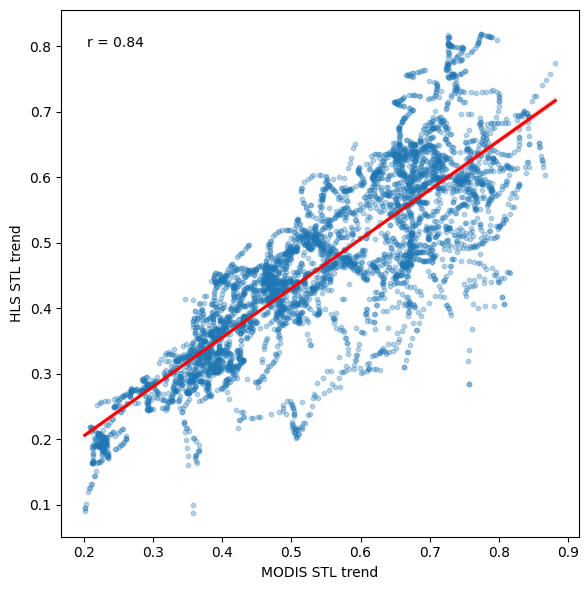

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

sample = matched.sample(
    min(5000,len(matched)),
    random_state=42
)

plt.figure(figsize=(6,6))

sns.regplot(
    data=sample,
    x="trend",
    y="hls_ndvi_trend",
    scatter_kws={"alpha":0.3,"s":10},
    line_kws={"color":"red"}
)

plt.xlabel("MODIS STL trend")
plt.ylabel("HLS STL trend")

plt.text(
    0.05,
    0.95,
    f"r = {0.840:.2f}",
    transform=plt.gca().transAxes,
    va="top"
)

plt.tight_layout()
plt.show()

The increasing spread at higher NDVI values is scientifically interesting.

The figure suggests:

Low and moderate NDVI values show extremely tight agreement.
High NDVI values show greater dispersion.
HLS sometimes records substantially lower and substantially higher values than MODIS at the same MODIS STL value.

That is exactly what we would expect if:

MODIS is averaging heterogeneous canopies within 250 m pixels.
HLS is retaining finer-scale variability.

This supports your earlier hypothesis:

HLS may provide additional information in heterogeneous forest conditions, particularly mixed forests.

###Analysis 1: Overall MODIS vs HLS comparison
Are mean NDVI values different?
Is HLS more variable
How strongly do sensors agree?

Metrics

In [47]:
from scipy.stats import pearsonr

df = matched

print(df[[
    "trend",
    "hls_ndvi_trend"
]].describe())

r,p = pearsonr(
    df["trend"].dropna(),
    df["hls_ndvi_trend"].dropna()
)

print(f"Correlation = {r:.3f}")
print(f"P-value = {p:.5f}")

              trend  hls_ndvi_trend
count  10729.000000    10729.000000
mean       0.544887        0.463102
std        0.157189        0.140902
min        0.200711        0.087541
25%        0.413816        0.360125
50%        0.544003        0.459989
75%        0.675744        0.574654
max        0.884339        0.819189
Correlation = 0.840
P-value = 0.00000


Check merge quality

In [48]:
print("Total rows:", len(combined))

print(
    "Rows with HLS:",
    combined["hls_ndvi_trend"].notna().sum()
)

print(
    "Rows with MODIS:",
    combined["trend"].notna().sum()
)

print(
    "Rows with both:",
    combined[
        ["trend","hls_ndvi_trend"]
    ].dropna().shape[0]
)


Total rows: 88724
Rows with HLS: 11957
Rows with MODIS: 82531
Rows with both: 10729


In [49]:
matched = combined[
    [
        "site_id",
        "date",
        "trend",
        "hls_ndvi_trend",
        "forest_type",
        "climate",
        "%_mort",
        "mort_year observed"
    ]
].dropna(
    subset=["trend","hls_ndvi_trend"]
)

print(matched.shape)

(10729, 8)


QUICK PLOT

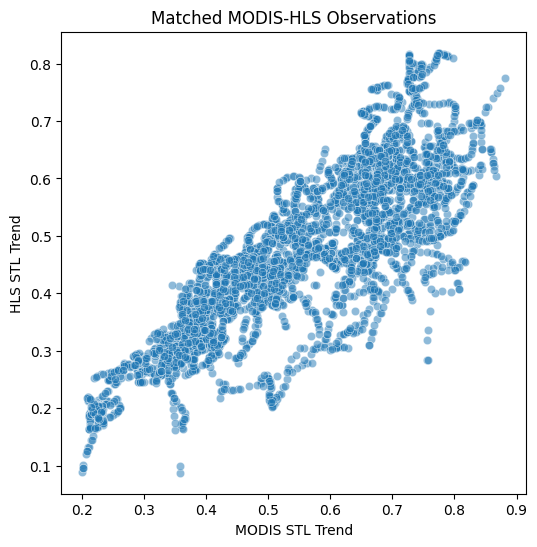

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

sns.scatterplot(
    data=matched.sample(
        min(5000, len(matched)),
        random_state=42
    ),
    x="trend",
    y="hls_ndvi_trend",
    alpha=0.5
)

plt.xlabel("MODIS STL Trend")
plt.ylabel("HLS STL Trend")

plt.title("Matched MODIS-HLS Observations")

plt.show()

Statistical test

In [51]:
from scipy.stats import ttest_rel, wilcoxon

tmp = df[[
    "trend",
    "hls_ndvi_trend"
]].dropna()

t,p = ttest_rel(
    tmp["trend"],
    tmp["hls_ndvi_trend"]
)

print("Paired t-test")
print(t,p)

w,p2 = wilcoxon(
    tmp["trend"],
    tmp["hls_ndvi_trend"]
)

print("Wilcoxon")
print(w,p2)

Paired t-test
98.6748473511112 0.0
Wilcoxon
3355803.0 0.0


Calculate mean difference and Cohen's D too

In [52]:
difference = df["hls_ndvi_trend"] - df["trend"]

print("Mean difference:", difference.mean())
print("Median difference:", difference.median())
print("Std difference:", difference.std())

Mean difference: -0.08178477683018404
Median difference: -0.06208634753964526
Std difference: 0.08585105419147372


In [53]:
cohens_d = difference.mean() / difference.std()
print(cohens_d)


-0.9526356734977225


Is Cohen's D consistent across forest types?

In [54]:
import pandas as pd
import numpy as np

effect_sizes = []

for forest, df in matched.groupby("forest_type"):

    d = df["hls_ndvi_trend"] - df["trend"]
    d = d.dropna()

    if len(d) < 10:
        continue

    cohens_d = d.mean() / d.std()

    effect_sizes.append({
        "forest_type": forest,
        "n": len(d),
        "mean_diff": d.mean(),
        "median_diff": d.median(),
        "sd_diff": d.std(),
        "cohens_d": cohens_d
    })

effect_df = pd.DataFrame(effect_sizes)

print(effect_df.round(3))

  forest_type     n  mean_diff  median_diff  sd_diff  cohens_d
0     Conifer  5060     -0.053       -0.040    0.072    -0.743
1   Deciduous  2794     -0.068       -0.063    0.059    -1.146
2       Mixed  2530     -0.159       -0.163    0.095    -1.674
3     conifer   230     -0.038       -0.047    0.036    -1.058
4       mixed   115     -0.069       -0.068    0.019    -3.589


Clean forest type labels (multiple spellings)

In [55]:
matched["forest_type"] = (
    matched["forest_type"]
    .astype(str)
    .str.strip()
    .str.title()
)

Check results

In [56]:
print(matched["forest_type"].value_counts())

forest_type
Conifer      5290
Deciduous    2794
Mixed        2645
Name: count, dtype: int64


Recalculate effect size

In [57]:
effect_sizes = []

for forest, df in matched.groupby("forest_type"):

    diff = (
        df["hls_ndvi_trend"] -
        df["trend"]
    ).dropna()

    effect_sizes.append({
        "forest_type": forest,
        "n": len(diff),
        "mean_diff": diff.mean(),
        "median_diff": diff.median(),
        "sd_diff": diff.std(),
        "cohens_d": diff.mean()/diff.std()
    })

effect_df = pd.DataFrame(effect_sizes)

print(effect_df.round(3))

  forest_type     n  mean_diff  median_diff  sd_diff  cohens_d
0     Conifer  5290     -0.053       -0.041    0.071    -0.746
1   Deciduous  2794     -0.068       -0.063    0.059    -1.146
2       Mixed  2645     -0.155       -0.159    0.095    -1.637


Publication quality figure

/tmp/ipykernel_2955/222808630.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


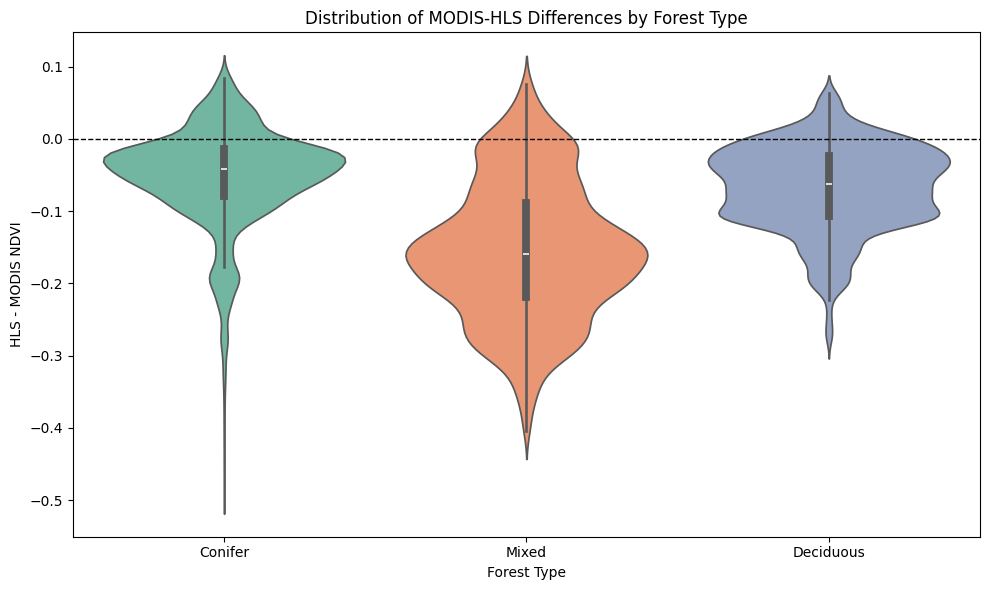

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt

matched["difference"] = (
    matched["hls_ndvi_trend"] -
    matched["trend"]
)

plt.figure(figsize=(10,6))

sns.violinplot(
    data=matched,
    x="forest_type",
    y="difference",
    inner="box",
    palette="Set2"
)

plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.ylabel("HLS - MODIS NDVI")
plt.xlabel("Forest Type")
plt.title("Distribution of MODIS-HLS Differences by Forest Type")

plt.tight_layout()
plt.show()

Forest type effect size bar chart

/tmp/ipykernel_2955/3218749725.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


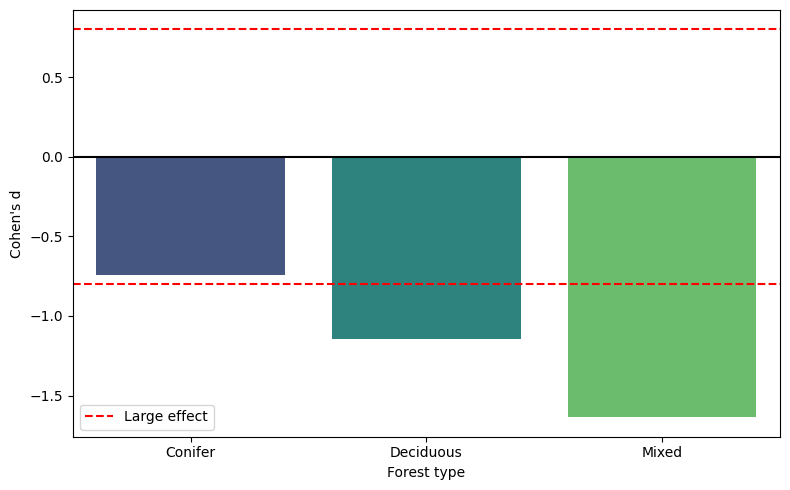

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.barplot(
    data=effect_df,
    x="forest_type",
    y="cohens_d",
    palette="viridis"
)

plt.axhline(0, color="black")
plt.axhline(0.8, ls="--", color="red", label="Large effect")
plt.axhline(-0.8, ls="--", color="red")

plt.ylabel("Cohen's d")
plt.xlabel("Forest type")
#plt.title("MODIS–HLS Effect Size by Forest Type")

plt.legend()
plt.tight_layout()
plt.show()

###Analysis 2 - Mortality detection sensitivity
Calculate site level decline

Create 'relative year' column

In [117]:
print("Columns:")
for col in matched.columns:
    print(col)

print("\nPotential year columns:")
print([c for c in matched.columns if "year" in c.lower()])

print("\nPotential mortality columns:")
print([c for c in matched.columns if "mort" in c.lower()])

Columns:
site_id
date
trend
hls_ndvi_trend
forest_type
climate
%_mort
mort_year
difference
year
relative_year
plot_id
start_date
end_date
event_date
in_drought
sensor_difference
mortality_group

Potential year columns:
['mort_year', 'year', 'relative_year']

Potential mortality columns:
['%_mort', 'mort_year', 'mortality_group']


In [61]:
print(matched["date"].head())
print(matched["date"].dtype)

960   2016-01-01
961   2016-01-17
962   2016-02-02
963   2016-02-18
964   2016-03-05
Name: date, dtype: datetime64[ns]
datetime64[ns]


Create a year column

In [118]:
matched["date"] = pd.to_datetime(matched["date"])

matched["year"] = matched["date"].dt.year

Then create relative year

In [119]:
matched["relative_year"] = (
    matched["year"] -
    matched["mort_year observed"]
)

KeyError: 'mort_year observed'

Rename mort_year observed

In [120]:
matched = matched.rename(
    columns={"mort_year observed": "mort_year"}
)

In [121]:
matched["relative_year"] = (
    matched["year"] -
    matched["mort_year"]
)

In [122]:
# Save mortality-aligned dataset

output_file = "MODIS_HLS_Mortality_Aligned.csv"

combined.to_csv(output_file, index=False)

print(f"Saved: {output_file}")
print(f"Shape: {combined.shape}")

Saved: MODIS_HLS_Mortality_Aligned.csv
Shape: (88724, 27)


Verify

In [123]:
print(
    matched[
        ["date", "year", "mort_year", "relative_year"]
    ].head()
)


        date  year  mort_year  relative_year
0 2016-01-01  2016     2016.0            0.0
1 2016-01-01  2016     2016.0            0.0
2 2016-01-17  2016     2016.0            0.0
3 2016-01-17  2016     2016.0            0.0
4 2016-02-02  2016     2016.0            0.0


In [67]:
matched["relative_year"].value_counts().sort_index()

,count
relative_year,
-7.0,69
-6.0,69
-5.0,115
-4.0,161
-3.0,184
-2.0,207
-1.0,207
0.0,368
1.0,368


###Save mortality aligned dataset with 'relative year' column

Mortality aligned MODIS v HLS trajectories

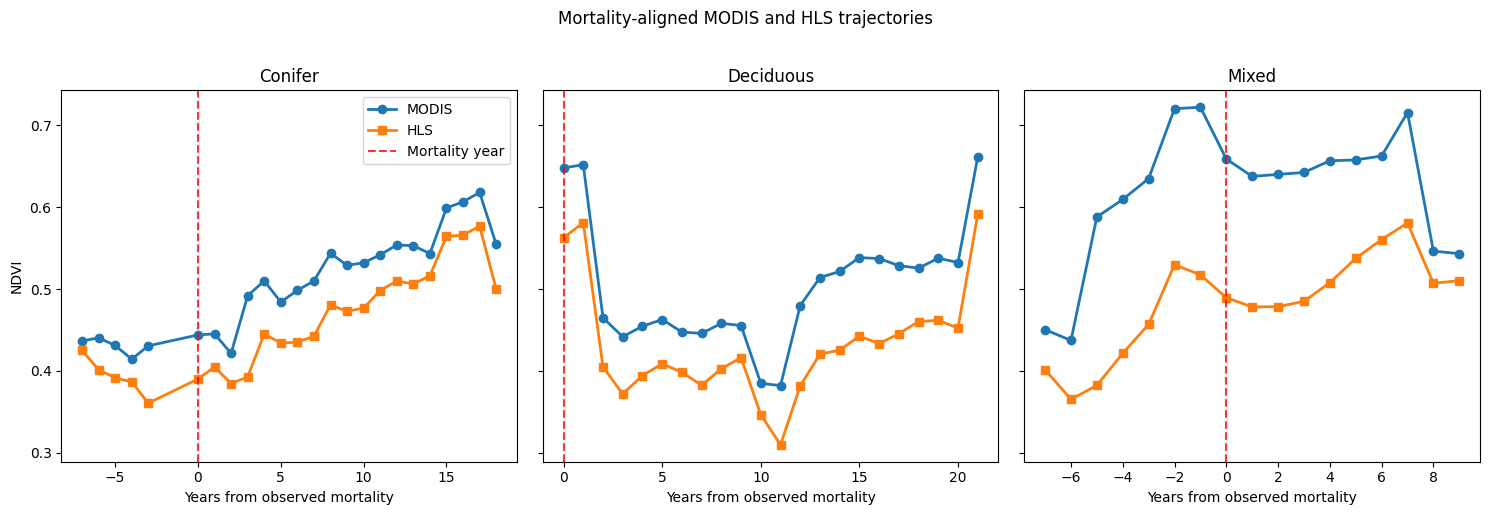

In [68]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Mean trajectory by relative year

traj = (
    matched
    .groupby(["relative_year","forest_type"])
    .agg(
        modis_mean=("trend","mean"),
        hls_mean=("hls_ndvi_trend","mean")
    )
    .reset_index()
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(15,5),
    sharey=True
)

forests = ["Conifer","Deciduous","Mixed"]

for ax, forest in zip(axes, forests):

    df = traj[traj["forest_type"] == forest]

    ax.plot(
        df["relative_year"],
        df["modis_mean"],
        marker="o",
        lw=2,
        label="MODIS"
    )

    ax.plot(
        df["relative_year"],
        df["hls_mean"],
        marker="s",
        lw=2,
        label="HLS"
    )

    ax.axvline(
        0,
        color="red",
        ls="--",
        alpha=0.8,
        label="Mortality year"
    )

    ax.set_title(forest)
    ax.set_xlabel("Years from observed mortality")

axes[0].set_ylabel("NDVI")
axes[0].legend()

plt.suptitle(
    "Mortality-aligned MODIS and HLS trajectories",
    y=1.02
)

plt.tight_layout()
plt.show()

Plot sensor difference through time

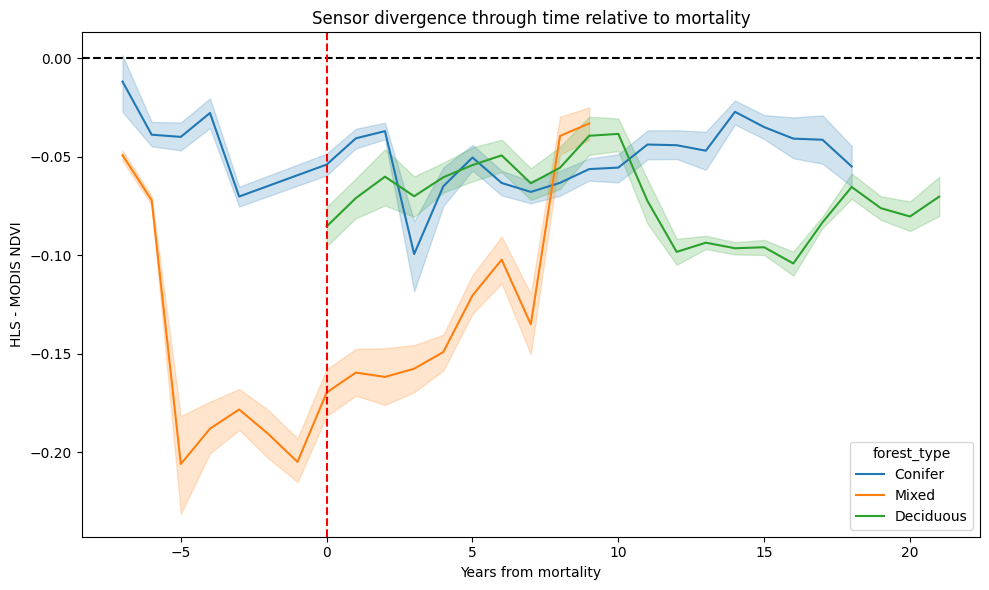

In [69]:
matched["difference"] = (
    matched["hls_ndvi_trend"] -
    matched["trend"]
)

plt.figure(figsize=(10,6))

sns.lineplot(
    data=matched,
    x="relative_year",
    y="difference",
    hue="forest_type",
    estimator="mean",
    errorbar=("ci",95)
)

plt.axhline(
    0,
    color="black",
    ls="--"
)

plt.axvline(
    0,
    color="red",
    ls="--",
    label="Mortality"
)

plt.ylabel("HLS - MODIS NDVI")
plt.xlabel("Years from mortality")

plt.title(
    "Sensor divergence through time relative to mortality"
)

plt.tight_layout()
plt.show()

In [70]:
for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        print("\n", name)
        print(obj.columns.tolist()[:20])


 __
['hls_ndvi_raw', 'hls_ndvi_sg', 'hls_ndvi_trend']

 ___
['site_id', 'start_date', 'end_date', 'event_date']

 hls
['system:index', 'hls_ndvi_raw', 'date', 'month', 'site_id', 'year', '.geo']

 modis
['plot_id', 'date', 'ndvi', 'trend', 'residual', 'year', 'doy', 'country', 'event_date', 'climate', 'forest_type', 'quality', '%_mort', 'site_type', 'start_date', 'end_date', 'in_drought', 'lat', 'long', 'mort_year observed']

 hls_processed
['system:index', 'hls_ndvi_raw', 'date', 'month', 'site_id', 'year', '.geo', 'hls_ndvi_sg', 'hls_ndvi_trend', 'hls_ndvi_seasonal', 'hls_ndvi_residual']

 combined
['plot_id', 'date', 'ndvi', 'trend', 'residual', 'year', 'doy', 'country', 'event_date', 'climate', 'forest_type', 'quality', '%_mort', 'site_type', 'start_date', 'end_date', 'in_drought', 'lat', 'long', 'mort_year observed']

 _4
['hls_ndvi_raw', 'hls_ndvi_sg', 'hls_ndvi_trend']

 matched
['site_id', 'date', 'trend', 'hls_ndvi_trend', 'forest_type', 'climate', '%_mort', 'mort_year', 'dif

reattach drought metadata

In [71]:
meta = (
    modis[
        [
            "plot_id",
            "start_date",
            "end_date",
            "event_date",
            "in_drought"
        ]
    ]
    .drop_duplicates()
)

matched = matched.merge(
    meta,
    left_on="site_id",
    right_on="plot_id",
    how="left"
)

check

In [72]:
matched[
    [
        "site_id",
        "start_date",
        "end_date",
        "event_date"
    ]
].head()


,site_id,start_date,end_date,event_date
0,akam,2007-10-01,2008-02-28,2016
1,akam,2007-10-01,2008-02-28,2016
2,akam,2007-10-01,2008-02-28,2016
3,akam,2007-10-01,2008-02-28,2016
4,akam,2007-10-01,2008-02-28,2016


Verify before plotting

In [73]:
print(
    matched[
        [
            "start_date",
            "end_date",
            "event_date"
        ]
    ].notna().sum()
)

start_date    19733
end_date      19733
event_date    19733
dtype: int64


In [74]:
print(matched.columns.tolist())
print(matched["site_id"].unique()[:20])


['site_id', 'date', 'trend', 'hls_ndvi_trend', 'forest_type', 'climate', '%_mort', 'mort_year', 'difference', 'year', 'relative_year', 'plot_id', 'start_date', 'end_date', 'event_date', 'in_drought']
['akam' 'albatera' 'ama' 'arcalis' 'bav_control' 'bav_mort' 'buenafuente'
 'c1' 'c2' 'c3' 'ch' 'co' 'crete1' 'crete2' 'crete3' 'dqs' 'falgars'
 'harz_mort' 'hkk' 'hmg']


Individual site plots with drought windows

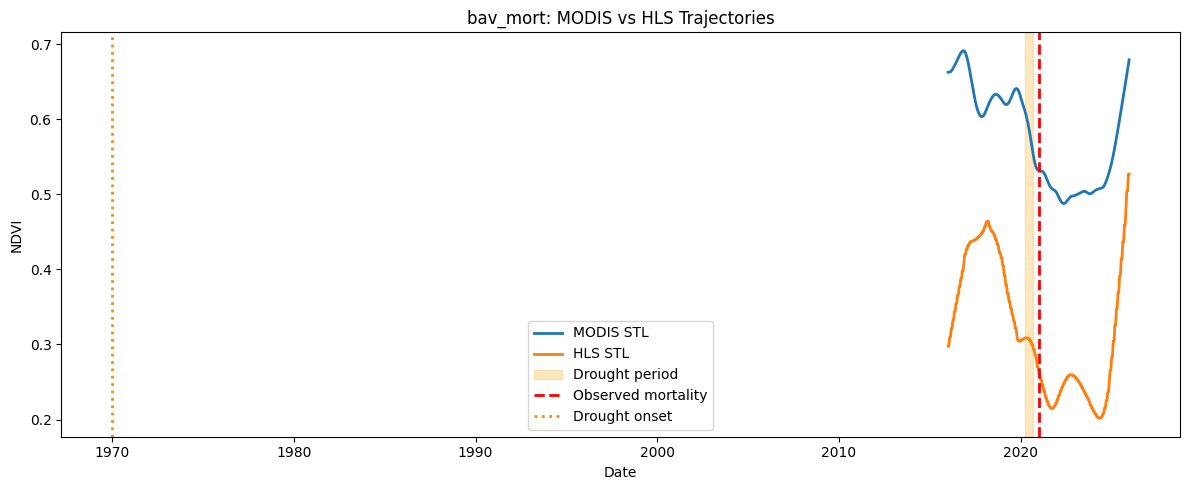

In [75]:
import pandas as pd
import matplotlib.pyplot as plt

site = "bav_mort"

df = (
    matched[matched["site_id"] == site]
    .copy()
    .sort_values("date")
)

# Convert dates
for col in ["date", "start_date", "end_date", "event_date"]:
    df[col] = pd.to_datetime(df[col])

plt.figure(figsize=(12,5))

plt.plot(
    df["date"],
    df["trend"],
    lw=2,
    label="MODIS STL"
)

plt.plot(
    df["date"],
    df["hls_ndvi_trend"],
    lw=2,
    label="HLS STL"
)

# Drought window
plt.axvspan(
    df["start_date"].iloc[0],
    df["end_date"].iloc[0],
    color="orange",
    alpha=0.25,
    label="Drought period"
)

# Mortality year
plt.axvline(
    pd.Timestamp(f"{int(df['mort_year'].iloc[0])}-01-01"),
    color="red",
    linestyle="--",
    linewidth=2,
    label="Observed mortality"
)

# Drought onset
plt.axvline(
    df["event_date"].iloc[0],
    color="darkorange",
    linestyle=":",
    linewidth=2,
    label="Drought onset"
)

plt.ylabel("NDVI")
plt.xlabel("Date")
plt.title(f"{site}: MODIS vs HLS Trajectories")

plt.legend()
plt.tight_layout()
plt.show()


Plot most informative sites automatically

In [76]:
top_sites = (
    matched.groupby("site_id")["%_mort"]
    .first()
    .sort_values(ascending=False)
    .head(6)
    .index
)

print(top_sites)

Index(['bav_mort', 'bav_control', 'ymort', 'harz_mort', 'stav', 'wald_mort'], dtype='object', name='site_id')


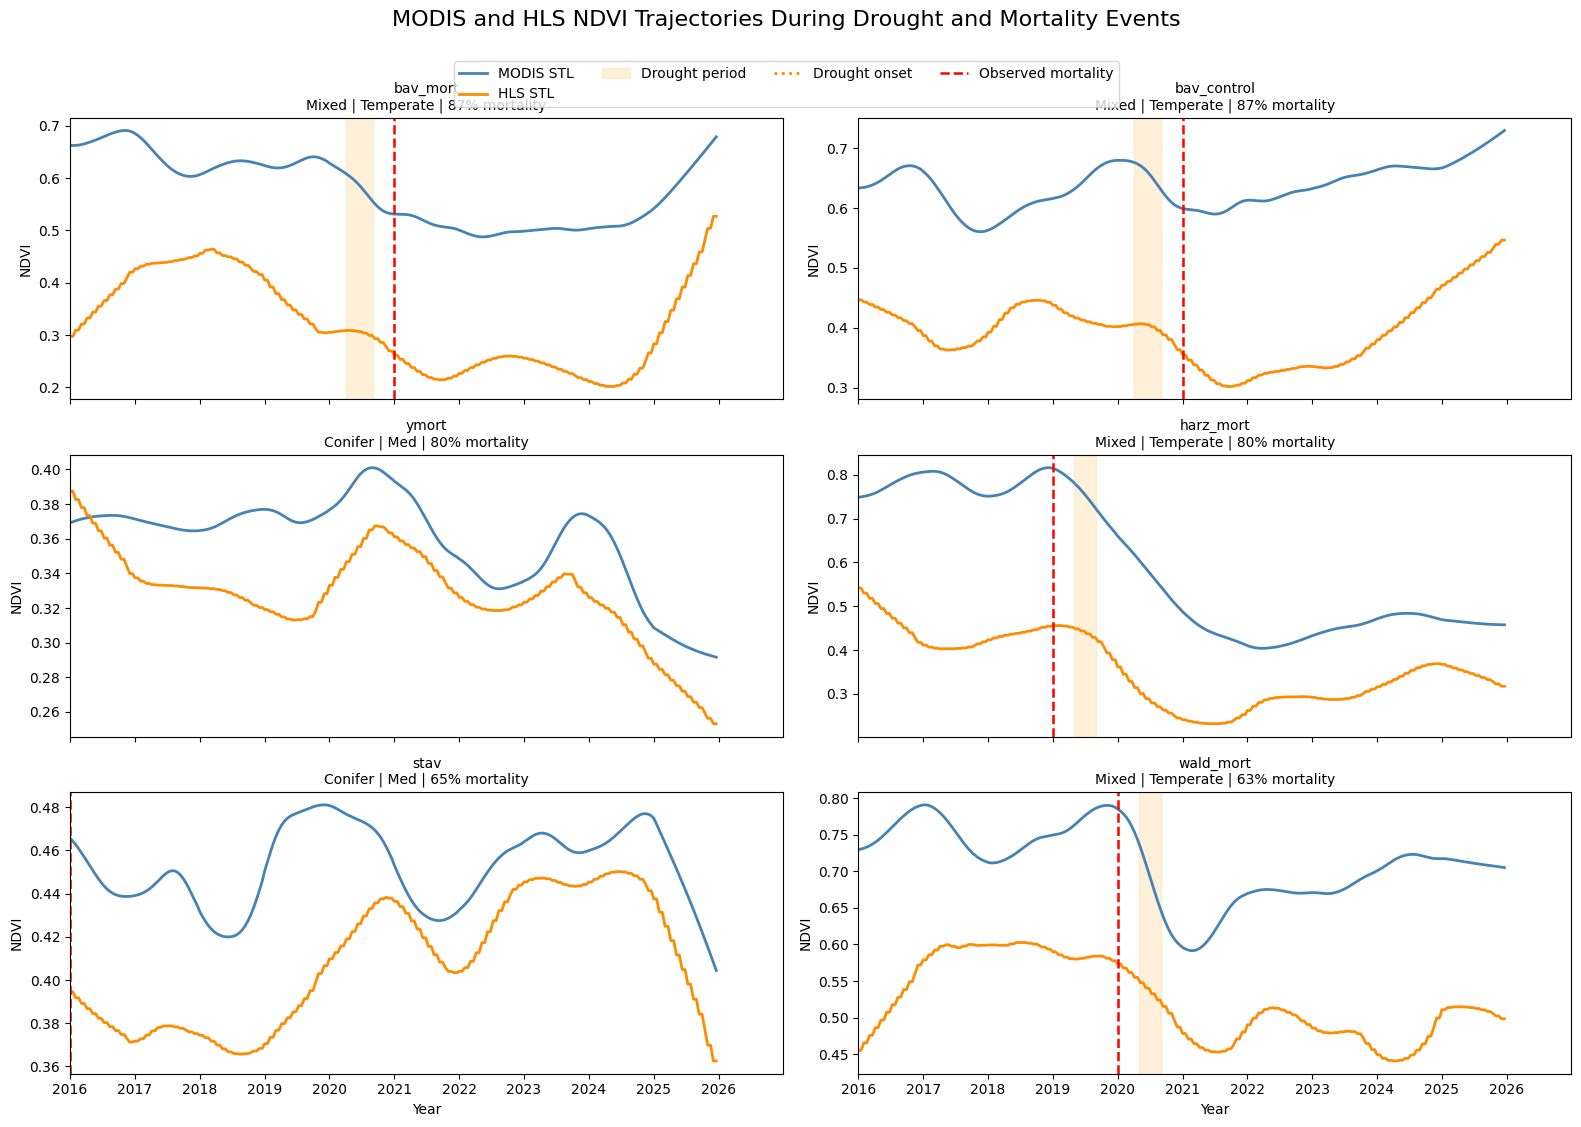

In [77]:
import pandas as pd
import matplotlib.pyplot as plt

# Select sites with highest mortality
top_sites = (
    matched.groupby("site_id")["%_mort"]
    .first()
    .sort_values(ascending=False)
    .head(6)
    .index
)

fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 11),
    sharex=True
)

for ax, site in zip(axes.flatten(), top_sites):

    df = (
        matched[matched["site_id"] == site]
        .copy()
        .sort_values("date")
    )

    # Convert date columns
    for col in ["date", "start_date", "end_date", "event_date"]:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col])

    # Plot trajectories
    ax.plot(
        df["date"],
        df["trend"],
        lw=2,
        color="steelblue",
        label="MODIS STL"
    )

    ax.plot(
        df["date"],
        df["hls_ndvi_trend"],
        lw=2,
        color="darkorange",
        label="HLS STL"
    )

    # Drought window
    if df["start_date"].notna().any() and df["end_date"].notna().any():

        ax.axvspan(
            df["start_date"].dropna().iloc[0],
            df["end_date"].dropna().iloc[0],
            color="orange",
            alpha=0.15,
            label="Drought period"
        )

    # Drought onset
    if df["event_date"].notna().any():

        ax.axvline(
            df["event_date"].dropna().iloc[0],
            color="darkorange",
            linestyle=":",
            linewidth=2,
            label="Drought onset"
        )

    # Mortality year
    if df["mort_year"].notna().any():

        mort_year = int(df["mort_year"].dropna().iloc[0])

        ax.axvline(
            pd.Timestamp(f"{mort_year}-01-01"),
            color="red",
            linestyle="--",
            linewidth=1.8,
            label="Observed mortality"
        )

    # Force axis to start at 2016
    ax.set_xlim(
        pd.Timestamp("2016-01-01"),
        pd.Timestamp("2026-12-31")
    )

    # Labels for subtitle
    mortality = df["%_mort"].dropna().iloc[0]

    forest = (
        df["forest_type"].dropna().iloc[0]
        if df["forest_type"].notna().any()
        else "Unknown"
    )

    climate = (
        df["climate"].dropna().iloc[0]
        if df["climate"].notna().any()
        else "Unknown"
    )

    ax.set_title(
        f"{site}\n"
        f"{forest} | {climate} | {mortality:.0f}% mortality",
        fontsize=10
    )

    ax.set_ylabel("NDVI")

# Shared x label
for ax in axes[-1, :]:
    ax.set_xlabel("Year")

# Shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=4,
    bbox_to_anchor=(0.5, 0.98)
)

fig.suptitle(
    "MODIS and HLS NDVI Trajectories During Drought and Mortality Events",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

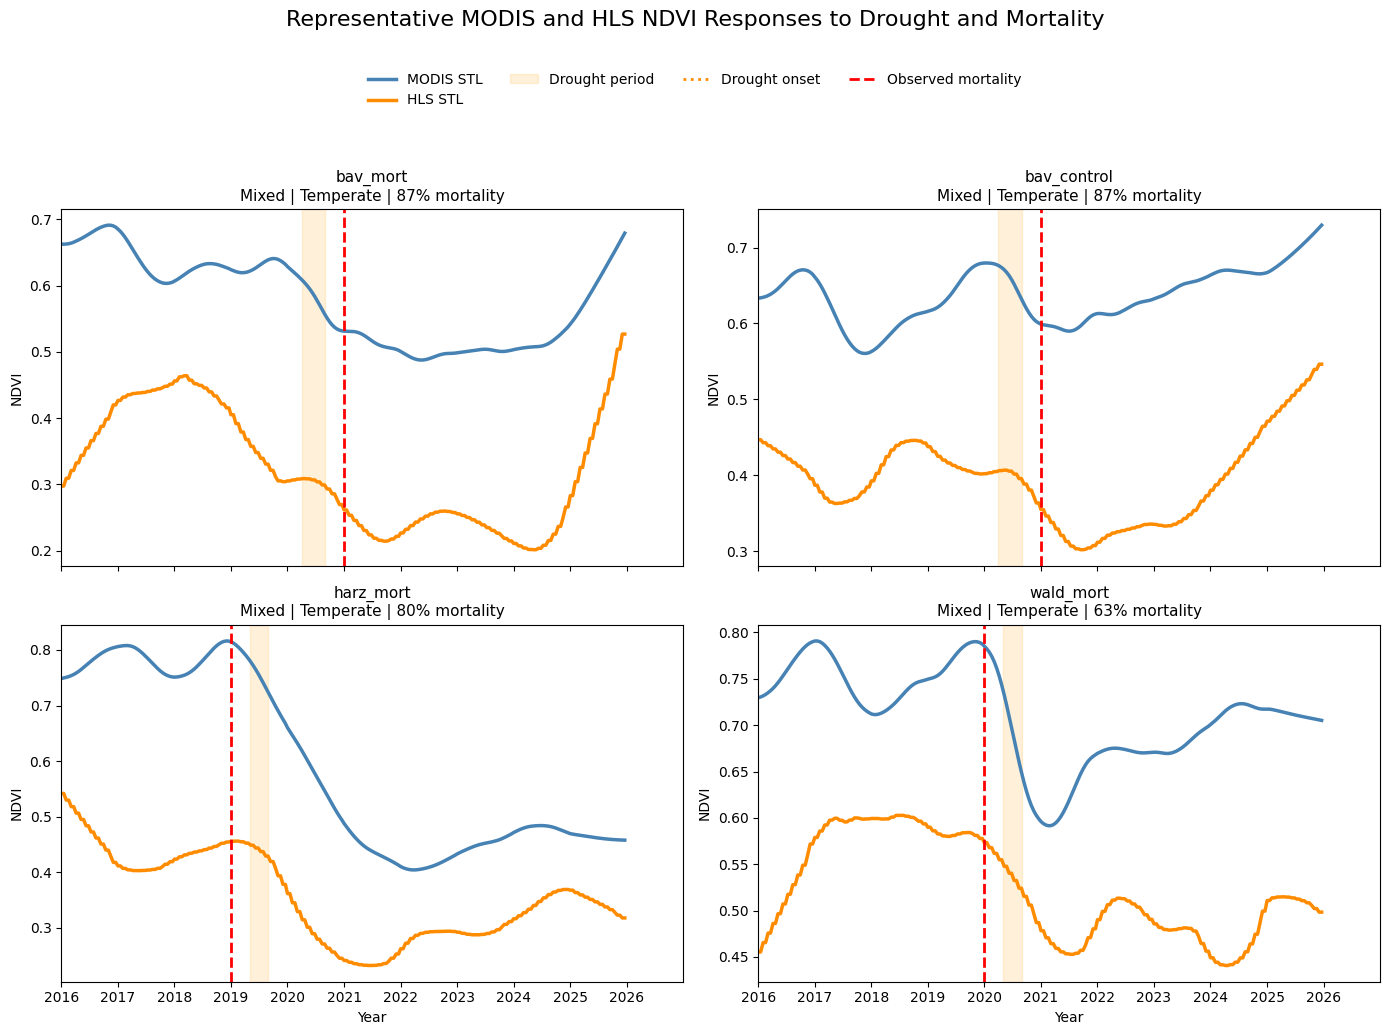

In [78]:
import pandas as pd
import matplotlib.pyplot as plt

sites = [
    "bav_mort",
    "bav_control",
    "harz_mort",
    "wald_mort"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    sharex=True
)

axes = axes.flatten()

for ax, site in zip(axes, sites):

    df = (
        matched[matched["site_id"] == site]
        .copy()
        .sort_values("date")
    )

    # Convert dates
    for col in ["date", "start_date", "end_date", "event_date"]:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col])

    # MODIS
    ax.plot(
        df["date"],
        df["trend"],
        color="steelblue",
        lw=2.5,
        label="MODIS STL"
    )

    # HLS
    ax.plot(
        df["date"],
        df["hls_ndvi_trend"],
        color="darkorange",
        lw=2.5,
        label="HLS STL"
    )

    # Drought period
    if (
        df["start_date"].notna().any()
        and
        df["end_date"].notna().any()
    ):

        ax.axvspan(
            df["start_date"].iloc[0],
            df["end_date"].iloc[0],
            color="orange",
            alpha=0.15,
            label="Drought period"
        )

    # Drought onset
    if df["event_date"].notna().any():

        ax.axvline(
            df["event_date"].iloc[0],
            color="darkorange",
            linestyle=":",
            linewidth=2,
            label="Drought onset"
        )

    # Mortality year
    if df["mort_year"].notna().any():

        ax.axvline(
            pd.Timestamp(
                f"{int(df['mort_year'].iloc[0])}-01-01"
            ),
            color="red",
            linestyle="--",
            linewidth=2,
            label="Observed mortality"
        )

    mortality = df["%_mort"].iloc[0]
    forest = df["forest_type"].iloc[0]
    climate = df["climate"].iloc[0]

    ax.set_title(
        f"{site}\n"
        f"{forest} | {climate} | {mortality:.0f}% mortality",
        fontsize=11
    )

    ax.set_ylabel("NDVI")

    # Start x-axis at 2016
    ax.set_xlim(
        pd.Timestamp("2016-01-01"),
        pd.Timestamp("2026-12-31")
    )

# x labels on bottom row only
for ax in axes[2:]:
    ax.set_xlabel("Year")

# SINGLE legend above plots
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.98),
    ncol=4,
    frameon=False
)

fig.suptitle(
    "Representative MODIS and HLS NDVI Responses to Drought and Mortality",
    fontsize=16,
    y=1.03
)

plt.tight_layout(rect=[0, 0, 1, 0.92])

plt.show()

###Mortality severity analysis
Start with a 60% threshold to match the MODIS analysis

In [79]:
site_metrics = []

for site, g in matched.groupby("site_id"):

    pre = g[g["relative_year"] < 0]
    post = g[g["relative_year"] > 0]

    if len(pre) < 2 or len(post) < 2:
        continue

    site_metrics.append({
        "site_id": site,
        "mortality": g["%_mort"].iloc[0],
        "forest_type": g["forest_type"].iloc[0],
        "modis_decline":
            pre["trend"].mean() -
            post["trend"].mean(),
        "hls_decline":
            pre["hls_ndvi_trend"].mean() -
            post["hls_ndvi_trend"].mean()
    })

site_metrics = pd.DataFrame(site_metrics)

print(site_metrics.head())
print(site_metrics.shape)

       site_id  mortality forest_type  modis_decline  hls_decline
0          ama        3.1       Mixed       0.046627     0.037927
1  bav_control       87.0       Mixed      -0.029174     0.007216
2     bav_mort       87.0       Mixed       0.099976     0.101840
3    harz_mort       80.0       Mixed       0.310009     0.142174
4          hkk        3.2       Mixed      -0.016836     0.001314
(9, 5)


In [80]:
import pandas as pd
from scipy.stats import ttest_ind, mannwhitneyu

severity_threshold = 60

site_metrics["severity"] = (
    site_metrics["mortality"]
    .apply(lambda x: "High" if x >= severity_threshold else "Low")
)

for sensor in ["modis_decline", "hls_decline"]:

    low = site_metrics.loc[
        site_metrics["severity"]=="Low",
        sensor
    ].dropna()

    high = site_metrics.loc[
        site_metrics["severity"]=="High",
        sensor
    ].dropna()

    t,p = ttest_ind(low, high, equal_var=False)

    u,p_u = mannwhitneyu(low, high)

    print(f"\n{sensor}")
    print("Low mean:", low.mean())
    print("High mean:", high.mean())
    print("T-test p =", p)
    print("Mann-Whitney p =", p_u)


modis_decline
Low mean: -0.008535743468944146
High mean: 0.11345191682536236
T-test p = 0.18462115047169575
Mann-Whitney p = 0.19047619047619047

hls_decline
Low mean: -0.007612136546760862
High mean: 0.08529082517774739
T-test p = 0.04297455280787023
Mann-Whitney p = 0.06349206349206349


Mortality relationship

In [81]:
from scipy.stats import pearsonr

for sensor in [
    "modis_decline",
    "hls_decline"
]:

    r,p = pearsonr(
        site_metrics[sensor],
        site_metrics["mortality"]
    )

    print(sensor,r,p)

modis_decline 0.5560191580557419 0.12005357550870556
hls_decline 0.6569811951253258 0.054539100908721036


In [82]:
severity_threshold = 60

site_metrics["severity"] = np.where(
    site_metrics["mortality"] >= severity_threshold,
    "High",
    "Low"
)

print(
    site_metrics.groupby("severity")[
        ["modis_decline","hls_decline"]
    ].describe()
)

         modis_decline                                                    \
                 count      mean       std       min       25%       50%   
severity                                                                   
High               4.0  0.113452  0.142355 -0.029174  0.047454  0.086486   
Low                5.0 -0.008536  0.031623 -0.032400 -0.025244 -0.016836   

                             hls_decline                                \
               75%       max       count      mean       std       min   
severity                                                                 
High      0.152484  0.310009         4.0  0.085291  0.056647  0.007216   
Low      -0.014825  0.046627         5.0 -0.007612  0.052342 -0.097726   

                                                  
               25%       50%       75%       max  
severity                                          
High      0.069254  0.095887  0.111923  0.142174  
Low       0.001314  0.005235  0.015189  0.03

###Analysis 3 - High v low mortality classes

In [83]:
threshold = 60

In [84]:
from scipy.stats import mannwhitneyu

for sensor in ["modis_decline", "hls_decline"]:

    low = site_metrics.loc[
        site_metrics["severity"]=="Low",
        sensor
    ]

    high = site_metrics.loc[
        site_metrics["severity"]=="High",
        sensor
    ]

    stat, p = mannwhitneyu(low, high)

    print("\n", sensor)
    print("Low mean:", low.mean())
    print("High mean:", high.mean())
    print("p =", p)


 modis_decline
Low mean: -0.008535743468944146
High mean: 0.11345191682536236
p = 0.19047619047619047

 hls_decline
Low mean: -0.007612136546760862
High mean: 0.08529082517774739
p = 0.06349206349206349


###Publication ready severity plot

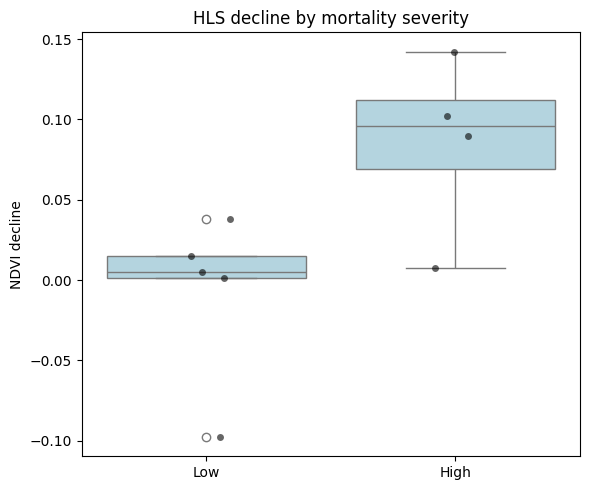

In [85]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.boxplot(
    data=site_metrics,
    x="severity",
    y="hls_decline",
    color="lightblue"
)

sns.stripplot(
    data=site_metrics,
    x="severity",
    y="hls_decline",
    color="black",
    alpha=0.6
)

plt.ylabel("NDVI decline")
plt.xlabel("")
plt.title("HLS decline by mortality severity")
plt.tight_layout()
plt.show()

###Continuous mortality-severity relationship

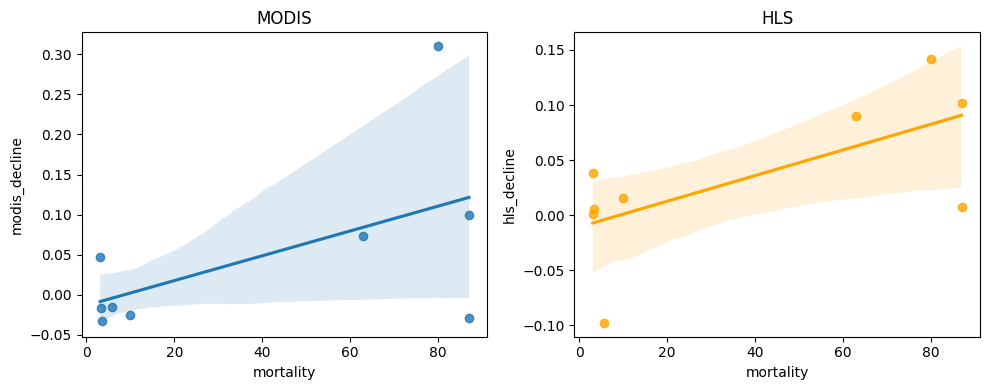

In [86]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.regplot(
    data=site_metrics,
    x="mortality",
    y="modis_decline",
    ax=ax[0],
    scatter_kws={"alpha":0.8}
)

ax[0].set_title("MODIS")

sns.regplot(
    data=site_metrics,
    x="mortality",
    y="hls_decline",
    ax=ax[1],
    scatter_kws={"alpha":0.8},
    color="orange"
)

ax[1].set_title("HLS")

plt.tight_layout()
plt.show()

###Threshold sensitivity analysis

In [87]:
import numpy as np
from scipy.stats import ttest_ind

results = []

for thresh in range(10,91,5):

    low = site_metrics.loc[
        site_metrics["mortality"] < thresh,
        "hls_decline"
    ]

    high = site_metrics.loc[
        site_metrics["mortality"] >= thresh,
        "hls_decline"
    ]

    if len(low) < 5 or len(high) < 5:
        continue

    t,p = ttest_ind(low, high, equal_var=False)

    diff = high.mean() - low.mean()

    results.append([thresh,diff,p])

results = pd.DataFrame(
    results,
    columns=["threshold","mean_difference","p"]
)

Plot

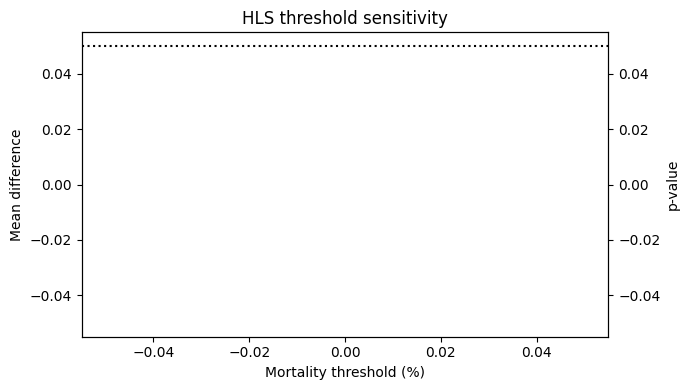

In [88]:
fig,ax1 = plt.subplots(figsize=(7,4))

ax1.plot(
    results["threshold"],
    results["mean_difference"],
    color="navy",
    marker="o"
)

ax1.set_ylabel("Mean difference")
ax1.set_xlabel("Mortality threshold (%)")

ax2 = ax1.twinx()

ax2.plot(
    results["threshold"],
    results["p"],
    color="red",
    linestyle="--"
)

ax2.axhline(
    0.05,
    color="black",
    linestyle=":"
)

ax2.set_ylabel("p-value")

plt.title("HLS threshold sensitivity")
plt.tight_layout()
plt.show()

###Compare MODSI and HLS threshold performance

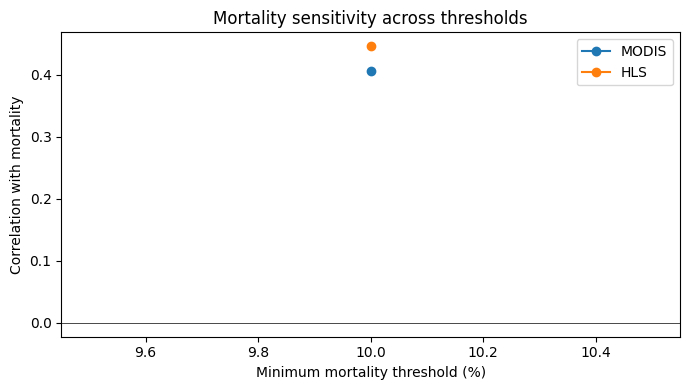

In [89]:
thresholds = range(10,91,5)

modis_r = []
hls_r = []

for t in thresholds:

    subset = site_metrics[
        site_metrics["mortality"] >= t
    ]

    if len(subset) < 5:
        modis_r.append(np.nan)
        hls_r.append(np.nan)
        continue

    modis_r.append(
        subset["modis_decline"].corr(
            subset["mortality"]
        )
    )

    hls_r.append(
        subset["hls_decline"].corr(
            subset["mortality"]
        )
    )

plt.figure(figsize=(7,4))

plt.plot(
    thresholds,
    modis_r,
    "-o",
    label="MODIS"
)

plt.plot(
    thresholds,
    hls_r,
    "-o",
    label="HLS"
)

plt.axhline(0, color="k", lw=0.5)

plt.xlabel("Minimum mortality threshold (%)")
plt.ylabel("Correlation with mortality")
plt.title("Mortality sensitivity across thresholds")

plt.legend()
plt.tight_layout()
plt.show()

Effect size comparison

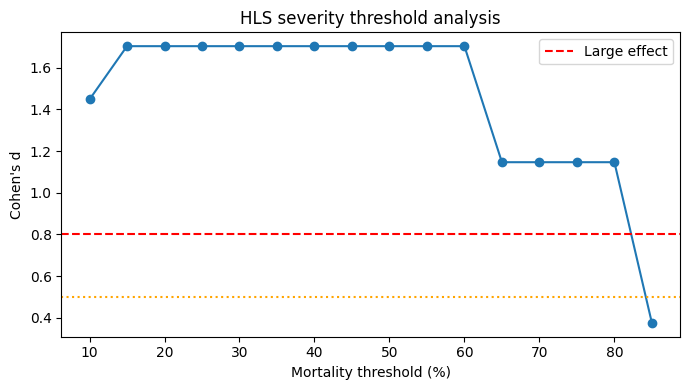

In [90]:
import numpy as np

results = []

for thresh in range(10,91,5):

    low = site_metrics.loc[
        site_metrics["mortality"] < thresh,
        "hls_decline"
    ]

    high = site_metrics.loc[
        site_metrics["mortality"] >= thresh,
        "hls_decline"
    ]

    if len(low) < 2 or len(high) < 2:
        continue

    pooled_sd = np.sqrt(
        (
            (low.std()**2) +
            (high.std()**2)
        ) / 2
    )

    d = (
        high.mean() -
        low.mean()
    ) / pooled_sd

    results.append([thresh,d])

results = pd.DataFrame(
    results,
    columns=["threshold","cohens_d"]
)

plt.figure(figsize=(7,4))

plt.plot(
    results["threshold"],
    results["cohens_d"],
    marker="o"
)

plt.axhline(
    0.8,
    color="red",
    linestyle="--",
    label="Large effect"
)

plt.axhline(
    0.5,
    color="orange",
    linestyle=":"
)

plt.xlabel("Mortality threshold (%)")
plt.ylabel("Cohen's d")
plt.title("HLS severity threshold analysis")
plt.legend()

plt.tight_layout()
plt.show()

HLS mortality sensitivity is strongest across moderate-to-high mortality thresholds (15-60%), where NDVI declines show very large effect sizes (Cohen's d ≈1.7). The relationship remains strong up to approximately 80% mortality before declining due to small sample sizes at the highest mortality levels.

In [91]:
from scipy.stats import ttest_ind

site_metrics["severity"] = np.where(
    site_metrics["mortality"] >= 60,
    "High",
    "Low"
)

for sensor in [
    "modis_decline",
    "hls_decline"
]:

    low = site_metrics[
        site_metrics["severity"]=="Low"
    ][sensor]

    high = site_metrics[
        site_metrics["severity"]=="High"
    ][sensor]

    t,p = ttest_ind(
        low,
        high,
        equal_var=False
    )

    print(sensor)
    print("Low mean =",low.mean())
    print("High mean =",high.mean())
    print("p =",p)

modis_decline
Low mean = -0.008535743468944146
High mean = 0.11345191682536236
p = 0.18462115047169575
hls_decline
Low mean = -0.007612136546760862
High mean = 0.08529082517774739
p = 0.04297455280787023


In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

forest_results = []

for forest in site_metrics["forest_type"].dropna().unique():

    df_forest = site_metrics[
        site_metrics["forest_type"] == forest
    ]

    for thresh in range(10,91,5):

        low = df_forest.loc[
            df_forest["mortality"] < thresh,
            "hls_decline"
        ]

        high = df_forest.loc[
            df_forest["mortality"] >= thresh,
            "hls_decline"
        ]

        if len(low) < 2 or len(high) < 2:
            continue

        pooled_sd = np.sqrt(
            (
                low.std()**2 +
                high.std()**2
            ) / 2
        )

        if pooled_sd == 0:
            continue

        d = (
            high.mean() - low.mean()
        ) / pooled_sd

        forest_results.append([
            forest,
            thresh,
            d
        ])

forest_results = pd.DataFrame(
    forest_results,
    columns=[
        "forest_type",
        "threshold",
        "cohens_d"
    ]
)

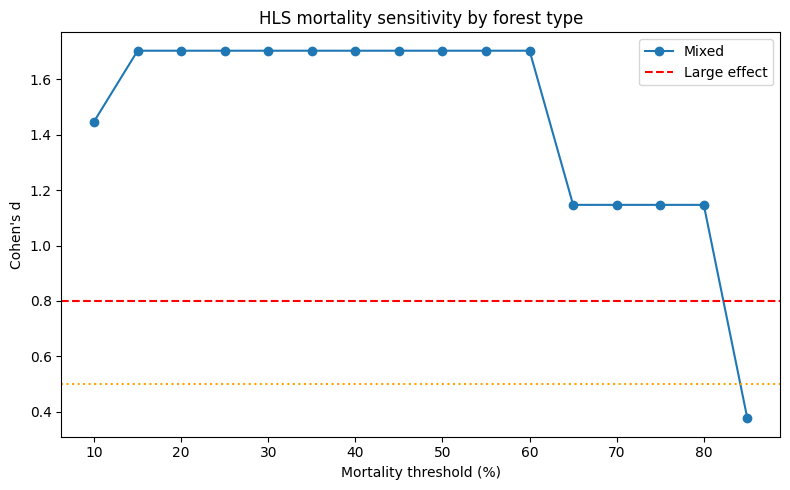

In [93]:
plt.figure(figsize=(8,5))

for forest, g in forest_results.groupby("forest_type"):

    plt.plot(
        g["threshold"],
        g["cohens_d"],
        marker="o",
        label=forest
    )

plt.axhline(
    0.8,
    color="red",
    linestyle="--",
    label="Large effect"
)

plt.axhline(
    0.5,
    color="orange",
    linestyle=":"
)

plt.xlabel("Mortality threshold (%)")
plt.ylabel("Cohen's d")
plt.title(
    "HLS mortality sensitivity by forest type"
)

plt.legend()
plt.tight_layout()
plt.show()

###Analysis 4 - FOrest type comparisons
Forest specific correlations

In [94]:
from scipy.stats import pearsonr

results = []

for forest, df_f in site_metrics.groupby("forest_type"):

    if len(df_f) < 4:
        continue

    r_mod, p_mod = pearsonr(
        df_f["mortality"],
        df_f["modis_decline"]
    )

    r_hls, p_hls = pearsonr(
        df_f["mortality"],
        df_f["hls_decline"]
    )

    results.append([
        forest,
        len(df_f),
        r_mod,
        p_mod,
        r_hls,
        p_hls
    ])

results = pd.DataFrame(
    results,
    columns=[
        "forest_type",
        "n",
        "modis_r",
        "modis_p",
        "hls_r",
        "hls_p"
    ]
)

print(results.round(3))

  forest_type  n  modis_r  modis_p  hls_r  hls_p
0       Mixed  9    0.556     0.12  0.657  0.055


scatter plots by forest type

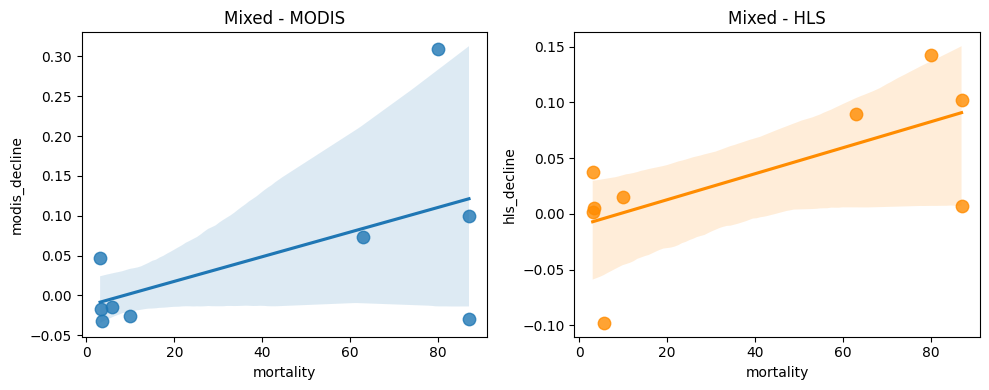

In [95]:
import seaborn as sns
import matplotlib.pyplot as plt

forests = site_metrics["forest_type"].dropna().unique()

fig, axes = plt.subplots(
    len(forests),
    2,
    figsize=(10,4*len(forests))
)

if len(forests) == 1:
    axes = [axes]

for i, forest in enumerate(forests):

    df_f = site_metrics[
        site_metrics["forest_type"] == forest
    ]

    sns.regplot(
        data=df_f,
        x="mortality",
        y="modis_decline",
        ax=axes[i][0],
        scatter_kws={"s":80}
    )

    axes[i][0].set_title(
        f"{forest} - MODIS"
    )

    sns.regplot(
        data=df_f,
        x="mortality",
        y="hls_decline",
        ax=axes[i][1],
        scatter_kws={"s":80},
        color="darkorange"
    )

    axes[i][1].set_title(
        f"{forest} - HLS"
    )

plt.tight_layout()
plt.show()

In [96]:
for sensor in ["modis_decline", "hls_decline"]:

    results = []

    for forest in site_metrics["forest_type"].unique():

        df_f = site_metrics[
            site_metrics["forest_type"] == forest
        ]

        if len(df_f) < 4:
            continue

        r = df_f["mortality"].corr(
            df_f[sensor]
        )

        results.append([forest, r])

    print(f"\n{sensor}")
    print(pd.DataFrame(
        results,
        columns=["forest_type","correlation"]
    ))


modis_decline
  forest_type  correlation
0       Mixed     0.556019

hls_decline
  forest_type  correlation
0       Mixed     0.656981


In [97]:
from scipy.stats import pearsonr

for forest,df_f in site_metrics.groupby(
    "forest_type"
):

    if len(df_f) < 5:
        continue

    print("\n",forest)

    for sensor in [
        "modis_decline",
        "hls_decline"
    ]:

        r,p = pearsonr(
            df_f[sensor],
            df_f["mortality"]
        )

        print(sensor,r,p)


 Mixed
modis_decline 0.5560191580557419 0.12005357550870556
hls_decline 0.6569811951253258 0.054539100908721036


Forest specific mean declines

In [98]:
forest_summary = (
    site_metrics
    .groupby("forest_type")
    [["modis_decline","hls_decline"]]
    .agg(["mean","std","count"])
)

print(forest_summary)

            modis_decline                 hls_decline                
                     mean       std count        mean       std count
forest_type                                                          
Mixed            0.045681  0.110603     9    0.033678  0.070503     9


Forest type mortality-aligned trajectories - add confidence intervals to the trajectory plots

In [99]:
summary = (
    matched.groupby(
        ["forest_type","relative_year"]
    )
    .agg(
        modis_mean=("trend","mean"),
        modis_se=("trend","sem"),
        hls_mean=("hls_ndvi_trend","mean"),
        hls_se=("hls_ndvi_trend","sem")
    )
    .reset_index()
)


plot

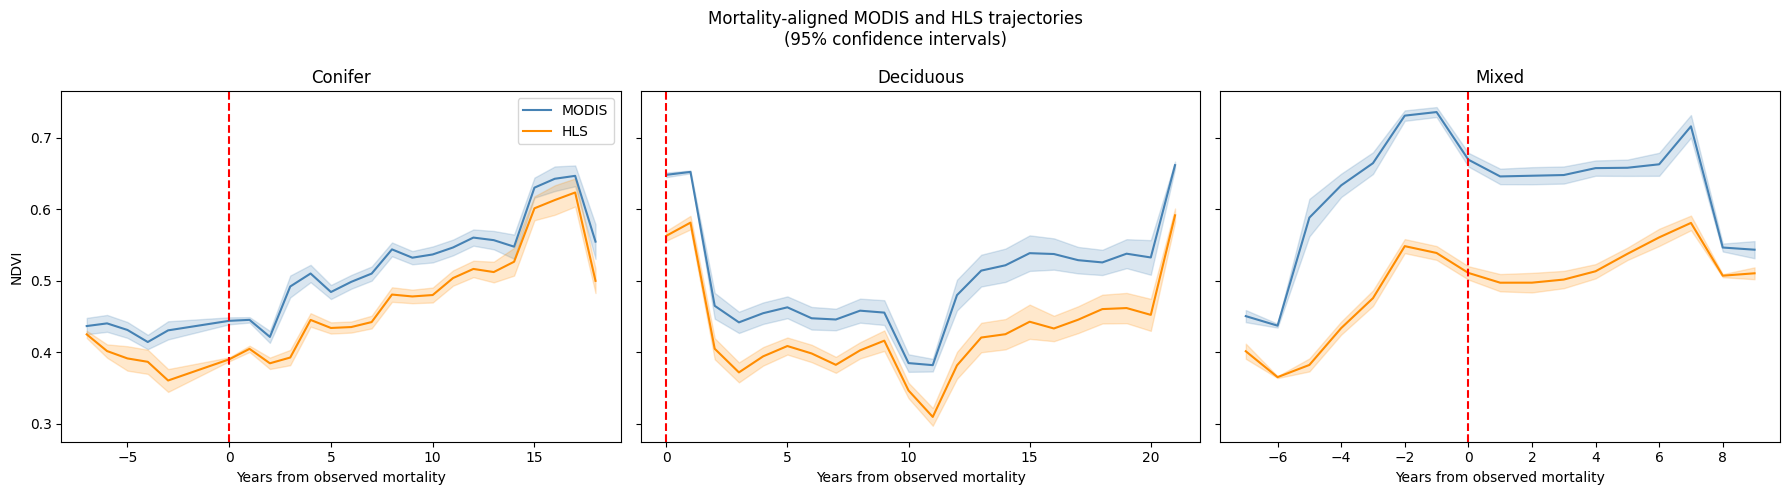

In [100]:
import matplotlib.pyplot as plt

forests = summary["forest_type"].unique()

fig, axes = plt.subplots(
    1,
    len(forests),
    figsize=(6*len(forests),5),
    sharey=True
)

if len(forests) == 1:
    axes = [axes]

for ax, forest in zip(axes, forests):

    d = summary[
        summary["forest_type"] == forest
    ]

    ax.plot(
        d["relative_year"],
        d["modis_mean"],
        color="steelblue",
        label="MODIS"
    )

    ax.fill_between(
        d["relative_year"],
        d["modis_mean"]-1.96*d["modis_se"],
        d["modis_mean"]+1.96*d["modis_se"],
        alpha=0.2,
        color="steelblue"
    )

    ax.plot(
        d["relative_year"],
        d["hls_mean"],
        color="darkorange",
        label="HLS"
    )

    ax.fill_between(
        d["relative_year"],
        d["hls_mean"]-1.96*d["hls_se"],
        d["hls_mean"]+1.96*d["hls_se"],
        alpha=0.2,
        color="darkorange"
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(forest)
    ax.set_xlabel(
        "Years from observed mortality"
    )

axes[0].set_ylabel("NDVI")
axes[0].legend()

plt.suptitle(
    "Mortality-aligned MODIS and HLS trajectories\n(95% confidence intervals)"
)

plt.tight_layout()
plt.show()

Does HLS have larger declines in Mixed forests?
Does HLS outperform MODIS in Deciduous forests?
Are Conifers almost identical?

These are likely the key ecological findings.

DIrect MODIS-HLS difference trajectory

In [101]:
matched["sensor_difference"] = (
    matched["trend"]
    - matched["hls_ndvi_trend"]
)

diff_summary = (
    matched.groupby(
        ["forest_type","relative_year"]
    )
    .agg(
        mean_diff=("sensor_difference","mean"),
        se=("sensor_difference","sem")
    )
    .reset_index()
)

plot

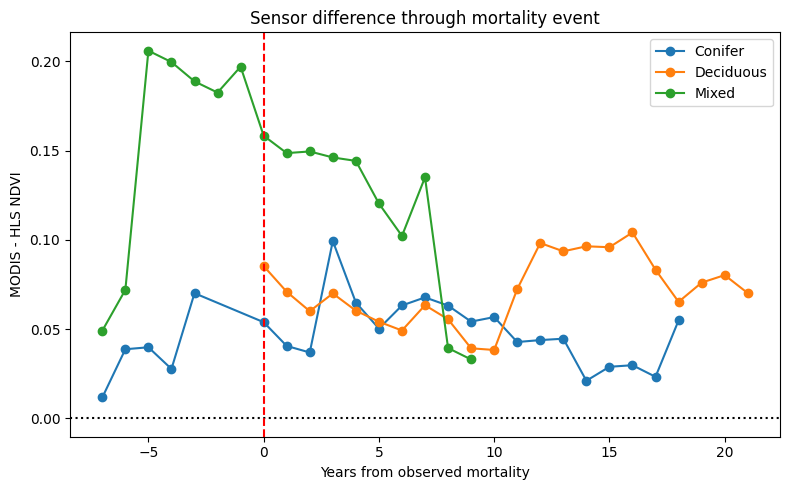

In [102]:
plt.figure(figsize=(8,5))

for forest, d in diff_summary.groupby("forest_type"):

    plt.plot(
        d["relative_year"],
        d["mean_diff"],
        marker="o",
        label=forest
    )

plt.axhline(
    0,
    color="black",
    linestyle=":"
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Years from observed mortality")
plt.ylabel("MODIS - HLS NDVI")
plt.title(
    "Sensor difference through mortality event"
)

plt.legend()
plt.tight_layout()
plt.show()


###High v low mortality severity trajectories

Create groups

In [103]:
threshold = 60  # adjust if desired

matched["mortality_group"] = np.where(
    matched["%_mort"] >= threshold,
    "High mortality",
    "Low mortality"
)

Calculate summaries

In [104]:
severity_summary = (
    matched.groupby(
        ["mortality_group", "relative_year"]
    )
    .agg(
        modis_mean=("trend", "mean"),
        modis_se=("trend", "sem"),
        hls_mean=("hls_ndvi_trend", "mean"),
        hls_se=("hls_ndvi_trend", "sem")
    )
    .reset_index()
)

Plot

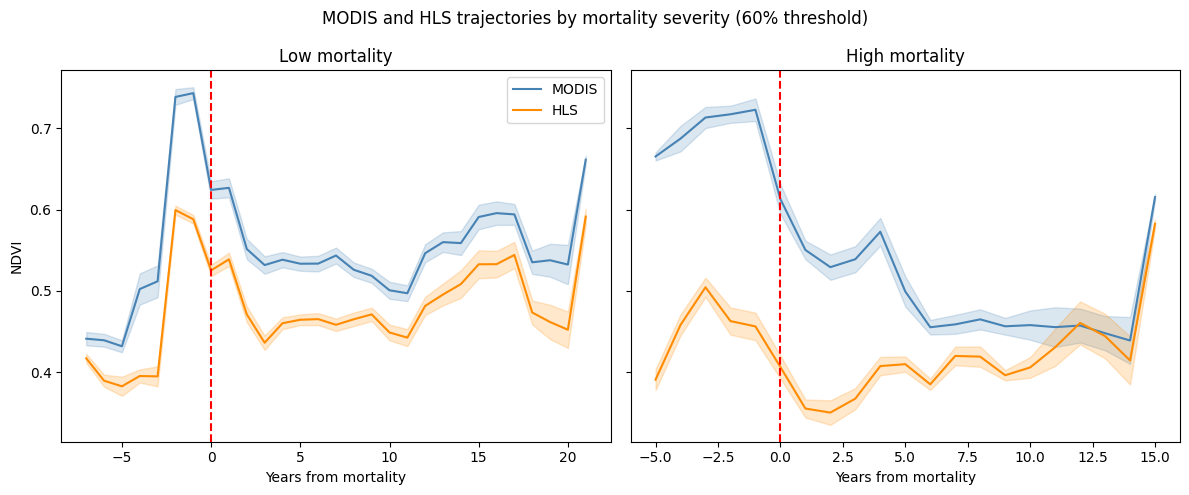

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(12,5), sharey=True)

for ax, group in zip(
    axes,
    ["Low mortality", "High mortality"]
):

    d = severity_summary[
        severity_summary["mortality_group"] == group
    ]

    ax.plot(
        d["relative_year"],
        d["modis_mean"],
        color="steelblue",
        label="MODIS"
    )

    ax.fill_between(
        d["relative_year"],
        d["modis_mean"] - 1.96*d["modis_se"],
        d["modis_mean"] + 1.96*d["modis_se"],
        color="steelblue",
        alpha=0.2
    )

    ax.plot(
        d["relative_year"],
        d["hls_mean"],
        color="darkorange",
        label="HLS"
    )

    ax.fill_between(
        d["relative_year"],
        d["hls_mean"] - 1.96*d["hls_se"],
        d["hls_mean"] + 1.96*d["hls_se"],
        color="darkorange",
        alpha=0.2
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(group)
    ax.set_xlabel("Years from mortality")

axes[0].set_ylabel("NDVI")
axes[0].legend()

plt.suptitle(
    f"MODIS and HLS trajectories by mortality severity ({threshold}% threshold)"
)

plt.tight_layout()
plt.show()

plot all trajectories together

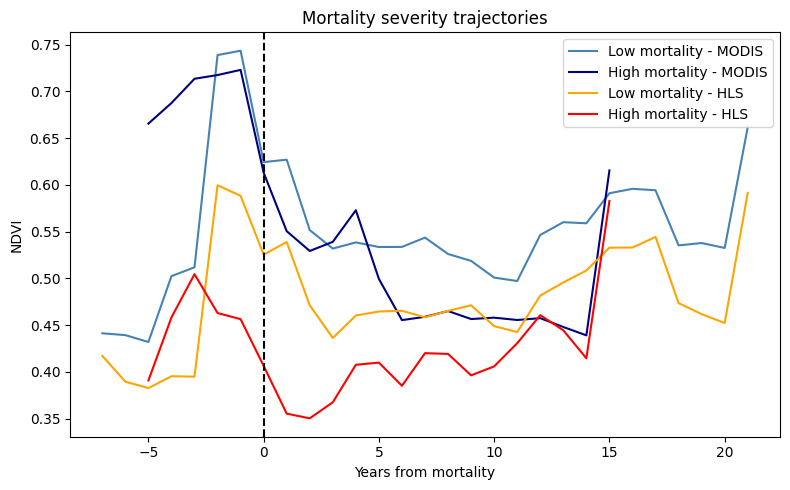

In [106]:
plt.figure(figsize=(8,5))

for group, colour, sensor in [

    ("Low mortality", "steelblue", "trend"),
    ("High mortality", "navy", "trend"),

    ("Low mortality", "orange", "hls_ndvi_trend"),
    ("High mortality", "red", "hls_ndvi_trend")

]:

    tmp = (
        matched[
            matched["mortality_group"] == group
        ]
        .groupby("relative_year")[sensor]
        .mean()
        .reset_index()
    )

    plt.plot(
        tmp["relative_year"],
        tmp[sensor],
        label=f"{group} - {'MODIS' if sensor=='trend' else 'HLS'}",
        color=colour
    )

plt.axvline(0, color="k", linestyle="--")

plt.xlabel("Years from mortality")
plt.ylabel("NDVI")
plt.title("Mortality severity trajectories")
plt.legend()

plt.tight_layout()
plt.show()

###Analysis 5 - CLimate comparisons

FIrstly see which climates we have

In [107]:
print(
    matched["climate"]
    .value_counts()
)

climate
Med            9660
semi-arid      3105
tropical       2828
Temperate      2300
continental    1380
Continental     460
Name: count, dtype: int64


Clean climate categories

In [108]:
matched["climate"] = (
    matched["climate"]
    .astype(str)
    .str.strip()
    .str.lower()
)

Check results

In [109]:
print(
    matched["climate"].value_counts()
)


climate
med            9660
semi-arid      3105
tropical       2828
temperate      2300
continental    1840
Name: count, dtype: int64


Calculate climate summaries

In [110]:
climate_summary = (
    matched.groupby(
        ["climate", "relative_year"]
    )
    .agg(
        modis_mean=("trend", "mean"),
        modis_se=("trend", "sem"),
        hls_mean=("hls_ndvi_trend", "mean"),
        hls_se=("hls_ndvi_trend", "sem")
    )
    .reset_index()
)

Plot MODIS and HLS by climate

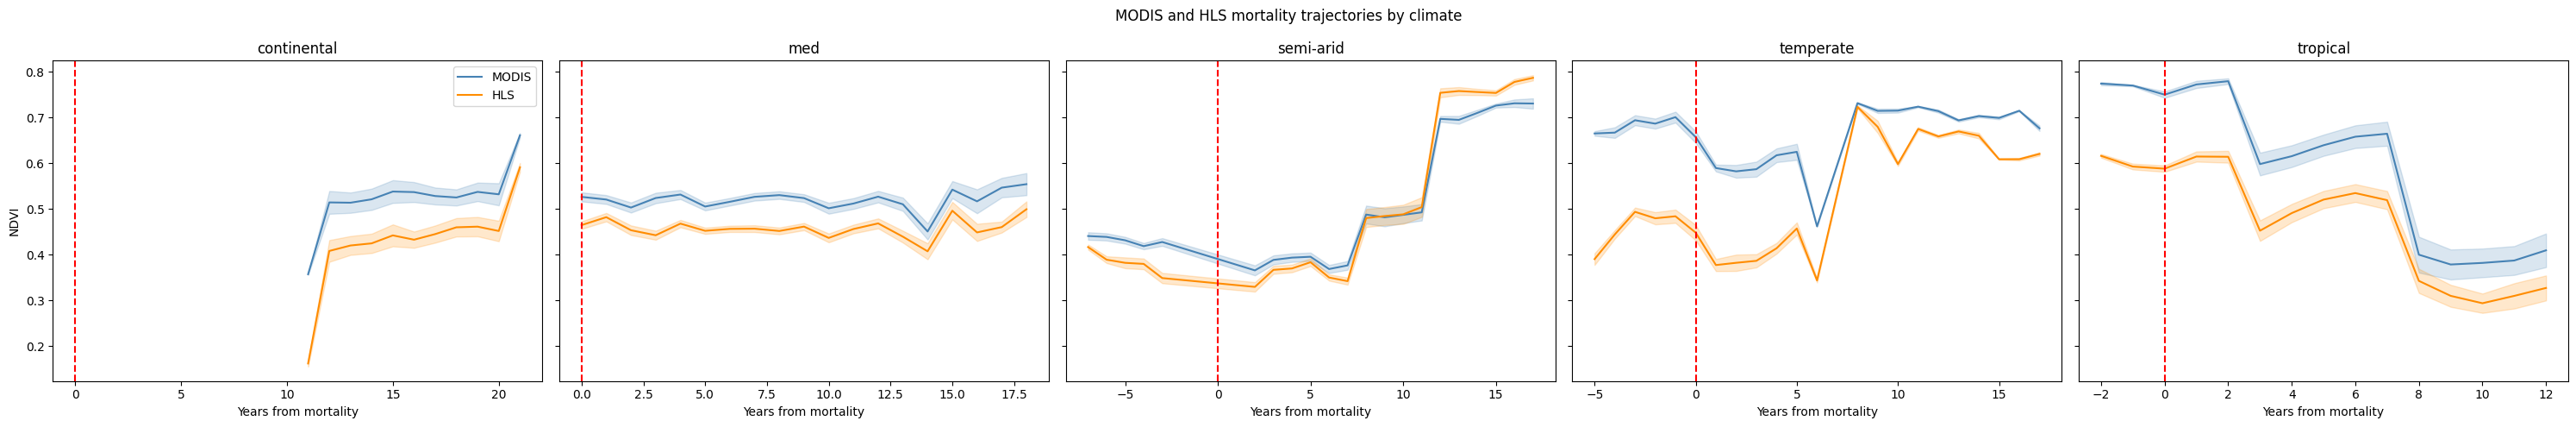

In [111]:
climates = climate_summary["climate"].dropna().unique()

fig, axes = plt.subplots(
    1,
    len(climates),
    figsize=(6*len(climates),5),
    sharey=True
)

if len(climates) == 1:
    axes = [axes]

for ax, climate in zip(axes, climates):

    d = climate_summary[
        climate_summary["climate"] == climate
    ]

    ax.plot(
        d["relative_year"],
        d["modis_mean"],
        color="steelblue",
        label="MODIS"
    )

    ax.fill_between(
        d["relative_year"],
        d["modis_mean"] - 1.96*d["modis_se"],
        d["modis_mean"] + 1.96*d["modis_se"],
        alpha=0.2,
        color="steelblue"
    )

    ax.plot(
        d["relative_year"],
        d["hls_mean"],
        color="darkorange",
        label="HLS"
    )

    ax.fill_between(
        d["relative_year"],
        d["hls_mean"] - 1.96*d["hls_se"],
        d["hls_mean"] + 1.96*d["hls_se"],
        alpha=0.2,
        color="darkorange"
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(climate)
    ax.set_xlabel(
        "Years from mortality"
    )

axes[0].set_ylabel("NDVI")
axes[0].legend()

plt.suptitle(
    "MODIS and HLS mortality trajectories by climate"
)

plt.tight_layout()
plt.show()

Quantify sensor difference

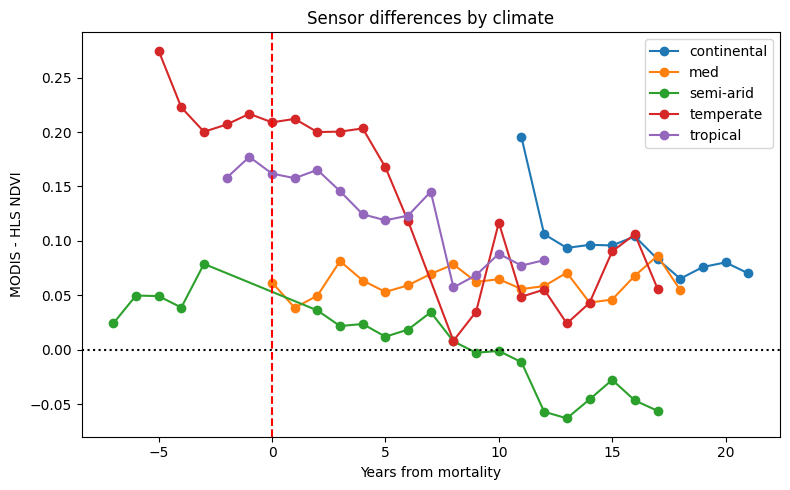

In [112]:
matched["sensor_difference"] = (
    matched["trend"]
    - matched["hls_ndvi_trend"]
)

climate_diff = (
    matched.groupby(
        ["climate", "relative_year"]
    )["sensor_difference"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8,5))

for climate, d in climate_diff.groupby("climate"):

    plt.plot(
        d["relative_year"],
        d["sensor_difference"],
        marker="o",
        label=climate
    )

plt.axvline(0, color="red", linestyle="--")
plt.axhline(0, color="black", linestyle=":")

plt.ylabel("MODIS - HLS NDVI")
plt.xlabel("Years from mortality")

plt.title(
    "Sensor differences by climate"
)

plt.legend()
plt.tight_layout()
plt.show()

###Analysis 8 - Final publication set
Figure 1 - Overall MODIS v HLS trajectories

Figure 2 - High v low mortality threshold

Figure 3 - Forest type trajectories

Figure 4 - Mortality severity scatterplots

In [113]:
# ===================================
# Figure 1 - overall trajectories
# ==================================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_style("whitegrid")
plt.rcParams["font.size"] = 12

plot_df = combined[
    combined["relative_year"].between(-5,5)
].copy()

summary = (
    plot_df
    .groupby("relative_year")
    .agg(
        modis_mean=("trend","mean"),
        modis_std=("trend","std"),
        modis_n=("trend","count"),

        hls_mean=("hls_ndvi_trend","mean"),
        hls_std=("hls_ndvi_trend","std"),
        hls_n=("hls_ndvi_trend","count")
    )
    .reset_index()
)

summary["modis_ci"] = (
    1.96 * summary["modis_std"] /
    np.sqrt(summary["modis_n"])
)

summary["hls_ci"] = (
    1.96 * summary["hls_std"] /
    np.sqrt(summary["hls_n"])
)

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(
    summary["relative_year"],
    summary["modis_mean"],
    color="steelblue",
    lw=3,
    label="MODIS"
)

ax.fill_between(
    summary["relative_year"],
    summary["modis_mean"]-summary["modis_ci"],
    summary["modis_mean"]+summary["modis_ci"],
    color="steelblue",
    alpha=0.2
)

ax.plot(
    summary["relative_year"],
    summary["hls_mean"],
    color="darkorange",
    lw=3,
    ls="--",
    label="HLS"
)

ax.fill_between(
    summary["relative_year"],
    summary["hls_mean"]-summary["hls_ci"],
    summary["hls_mean"]+summary["hls_ci"],
    color="darkorange",
    alpha=0.2
)

ax.axvline(0,color="black",ls="--")

ax.set_xlabel("Years Relative to Mortality")
ax.set_ylabel("NDVI Trend")
ax.set_title("MODIS and HLS Mortality Trajectories")
ax.legend

KeyError: 'relative_year'

###Combined mortality severity comparison

check mortality groups exist

if not, recreate them

In [114]:
threshold = 60

plot_df["mortality_group"] = np.where(
    plot_df["%_mort"] >= threshold,
    "High mortality",
    "Low mortality"
)

NameError: name 'plot_df' is not defined

publication ready version with 95% confidence intervals

In [115]:
summary = (
    plot_df
    .groupby(
        ["mortality_group", "relative_year"]
    )
    .agg(
        modis_mean=("trend", "mean"),
        modis_se=("trend", "sem"),
        hls_mean=("hls_ndvi_trend", "mean"),
        hls_se=("hls_ndvi_trend", "sem")
    )
    .reset_index()
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12,5),
    sharey=True
)

for ax, group in zip(
    axes,
    ["Low mortality", "High mortality"]
):

    d = summary[
        summary["mortality_group"] == group
    ]

    ax.plot(
        d["relative_year"],
        d["modis_mean"],
        color="steelblue",
        label="MODIS"
    )

    ax.fill_between(
        d["relative_year"],
        d["modis_mean"] - 1.96*d["modis_se"],
        d["modis_mean"] + 1.96*d["modis_se"],
        color="steelblue",
        alpha=0.2
    )

    ax.plot(
        d["relative_year"],
        d["hls_mean"],
        color="darkorange",
        label="HLS"
    )

    ax.fill_between(
        d["relative_year"],
        d["hls_mean"] - 1.96*d["hls_se"],
        d["hls_mean"] + 1.96*d["hls_se"],
        color="darkorange",
        alpha=0.2
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(group)
    ax.set_xlabel("Years from mortality")

axes[0].set_ylabel("NDVI")
axes[0].legend()

plt.suptitle(
    "MODIS and HLS trajectories by mortality severity"
)

plt.tight_layout()
plt.show()


NameError: name 'plot_df' is not defined

In [ ]:
# ======================================================
# Figure 3 - Forest type comparison
# =====================================================
forests = [
    "Conifer",
    "Deciduous",
    "Mixed"
]

fig, axes = plt.subplots(
    1,3,
    figsize=(15,4),
    sharey=True
)

for ax,forest in zip(axes,forests):

    d = combined[
        (combined["forest_type"]==forest) &
        (combined["relative_year"].between(-5,5))
    ]

    summary = (
        d.groupby("relative_year")
        [["trend","hls_ndvi_trend"]]
        .mean()
        .reset_index()
    )

    ax.plot(
        summary["relative_year"],
        summary["trend"],
        lw=3,
        color="steelblue",
        label="MODIS"
    )

    ax.plot(
        summary["relative_year"],
        summary["hls_ndvi_trend"],
        lw=3,
        ls="--",
        color="darkorange",
        label="HLS"
    )

    ax.axvline(0,color="k",ls="--")

    ax.set_title(forest)

axes[0].set_ylabel("NDVI Trend")

handles,labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2
)

plt.tight_layout()
plt.show()

better version chart with 95%

In [ ]:
# Restrict to ±5 years around mortality

plot_df = matched[
    matched["relative_year"].between(-5, 5)
].copy()

# Summary statistics

forest_summary = (
    plot_df.groupby(
        ["forest_type", "relative_year"]
    )
    .agg(
        modis_mean=("trend", "mean"),
        modis_se=("trend", "sem"),
        hls_mean=("hls_ndvi_trend", "mean"),
        hls_se=("hls_ndvi_trend", "sem")
    )
    .reset_index()
)

forests = ["Conifer", "Deciduous", "Mixed"]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
    sharey=True
)

for ax, forest in zip(axes, forests):

    d = forest_summary[
        forest_summary["forest_type"] == forest
    ]

    # MODIS

    ax.plot(
        d["relative_year"],
        d["modis_mean"],
        color="steelblue",
        linewidth=2,
        label="MODIS"
    )

    ax.fill_between(
        d["relative_year"],
        d["modis_mean"] - 1.96*d["modis_se"],
        d["modis_mean"] + 1.96*d["modis_se"],
        color="steelblue",
        alpha=0.15
    )

    # HLS

    ax.plot(
        d["relative_year"],
        d["hls_mean"],
        color="darkorange",
        linewidth=2,
        label="HLS"
    )

    ax.fill_between(
        d["relative_year"],
        d["hls_mean"] - 1.96*d["hls_se"],
        d["hls_mean"] + 1.96*d["hls_se"],
        color="darkorange",
        alpha=0.15
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--",
        linewidth=1.5
    )

    ax.set_title(forest)
    ax.set_xlabel("Years from mortality")

axes[0].set_ylabel("NDVI")

axes[0].legend(
    loc="upper left"
)

#plt.suptitle(
 #   "MODIS and HLS trajectories by forest type",
  #  fontsize=16
#)

plt.tight_layout()
plt.show()

In [ ]:
# ====================================
# Figure 4 - Climate comparison
# ====================================
g = sns.FacetGrid(
    combined[
        combined["relative_year"].between(-5,5)
    ],
    col="climate",
    col_wrap=3,
    height=4
)

def draw(data, **kwargs):

    plt.plot(
        data.groupby("relative_year")
        ["trend"]
        .mean(),
        color="steelblue",
        lw=2
    )

    plt.plot(
        data.groupby("relative_year")
        ["hls_ndvi_trend"]
        .mean(),
        color="darkorange",
        lw=2,
        ls="--"
    )

g.map_dataframe(draw)

plt.show()

recode climate classes

In [ ]:
matched["climate4"] = (
    matched["climate"]
    .astype(str)
    .str.strip()
    .str.lower()
)

matched["climate4"] = matched["climate4"].replace({
    "med": "Mediterranean",
    "mediterranean": "Mediterranean",

    "temperate": "Temperate",
    "continental": "Temperate",
    "boreal": "Temperate",

    "tropical": "Tropical",

    "semi-arid": "Semi-arid",
    "semi-arid": "Semi-arid"})


only 5 years pre and post on x axis

In [ ]:
matched_5yr = matched[
    matched["relative_year"].between(-5, 5)
].copy()

recalculate summary

In [ ]:
climate_summary = (
    matched_5yr.groupby(
        ["climate4", "relative_year"]
    )
    .agg(
        modis_mean=("trend", "mean"),
        modis_se=("trend", "sem"),
        hls_mean=("hls_ndvi_trend", "mean"),
        hls_se=("hls_ndvi_trend", "sem")
    )
    .reset_index()
)

In [ ]:
import matplotlib.pyplot as plt

climates = [
    "Temperate",
    "Mediterranean",
    "Tropical",
    "Semi-arid"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12,8),
    sharey=True
)

axes = axes.flatten()

for ax, climate in zip(axes, climates):

    d = climate_summary[
        climate_summary["climate4"] == climate
    ]

    ax.plot(
        d["relative_year"],
        d["modis_mean"],
        color="steelblue",
        lw=2,
        label="MODIS"
    )

    ax.fill_between(
        d["relative_year"],
        d["modis_mean"] - 1.96*d["modis_se"],
        d["modis_mean"] + 1.96*d["modis_se"],
        color="steelblue",
        alpha=0.2
    )

    ax.plot(
        d["relative_year"],
        d["hls_mean"],
        color="darkorange",
        lw=2,
        label="HLS"
    )

    ax.fill_between(
        d["relative_year"],
        d["hls_mean"] - 1.96*d["hls_se"],
        d["hls_mean"] + 1.96*d["hls_se"],
        color="darkorange",
        alpha=0.2
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--"
    )

    ax.set_title(climate)
    ax.set_xlabel("Years from mortality")

axes[0].set_ylabel("NDVI")
axes[2].set_ylabel("NDVI")
axes[0].legend()

plt.suptitle(
    "Mortality-aligned MODIS and HLS trajectories by climate"
)

plt.tight_layout()
plt.show()

In [ ]:
# ===================================
# Figure 5 - Mortality Severity relationships
# ===================================
import seaborn as sns

fig, axes = plt.subplots(
    1,2,
    figsize=(10,4)
)

sns.regplot(
    data=site_metrics,
    x="mortality",
    y="modis_decline",
    ax=axes[0],
    scatter_kws={"s":50}
)

axes[0].set_title(
    "MODIS"
)

sns.regplot(
    data=site_metrics,
    x="mortality",
    y="hls_decline",
    ax=axes[1],
    scatter_kws={"s":50},
    color="darkorange"
)

axes[1].set_title(
    "HLS"
)

plt.tight_layout()
plt.show()

In [ ]:
# ===================================
# Figure 6 - MODIS v HLS Direct COmparison
# ===================================
from scipy.stats import pearsonr

tmp = combined[
    ["trend","hls_ndvi_trend"]
].dropna()

r,p = pearsonr(
    tmp["trend"],
    tmp["hls_ndvi_trend"]
)

fig, ax = plt.subplots(figsize=(6,6))

sns.regplot(
    data=tmp,
    x="trend",
    y="hls_ndvi_trend",
    scatter_kws={"s":15},
    ax=ax
)

ax.text(
    0.05,
    0.95,
    f"r = {r:.2f}\np = {p:.001g}",
    transform=ax.transAxes,
    va="top"
)

ax.set_title(
    "MODIS vs HLS Trend Agreement"
)

plt.tight_layout()
plt.show()

Recreate the mixed sites by mortality severity

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(14, 8))

# --------------------------
# Individual site trajectories
# --------------------------

for mortality_class, colour in [
    ("High mortality", "red"),
    ("Low mortality", "green")
]:

    for site, df_site in (
        plot_df[
            plot_df["mortality_group"] == mortality_class
        ]
        .groupby("site_id")
    ):

        ax.plot(
            df_site["relative_year"],
            df_site["trend"],
            color=colour,
            alpha=0.5,
            lw=0.6
        )

# --------------------------
# Mean trajectories
# --------------------------

summary = (
    plot_df
    .groupby(
        ["mortality_group", "relative_year"]
    )
    .agg(
        mean_ndvi=("trend", "mean"),
        se=("trend", "sem")
    )
    .reset_index()
)

for mortality_class, colour in [
    ("High mortality", "red"),
    ("Low mortality", "green")
]:

    d = summary[
        summary["mortality_group"] == mortality_class
    ]

    ax.plot(
        d["relative_year"],
        d["mean_ndvi"],
        color=colour,
        lw=3,
        label=mortality_class
    )

    ax.fill_between(
        d["relative_year"],
        d["mean_ndvi"] - 1.96 * d["se"],
        d["mean_ndvi"] + 1.96 * d["se"],
        color=colour,
        alpha=0.25
    )

# --------------------------
# Mortality marker
# --------------------------

ax.axvline(
    0,
    color="black",
    linestyle="-.",
    linewidth=1.5
)

# Label at top of line

ymax = ax.get_ylim()[1]

ax.text(
    0,
    ymax,
    "Observed mortality",
    rotation=90,
    ha="right",
    va="top",
    fontsize=16
)

# --------------------------
# Formatting
# --------------------------

ax.set_xlabel(
    "Years Relative to Mortality",
    fontsize=18
)

ax.set_ylabel(
    "NDVI Trend",
    fontsize=18
)

ax.tick_params(labelsize=13)

ax.legend(
    title="Mortality Severity",
    frameon=False,
    fontsize=13,
    title_fontsize=14,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.show()

create mixed forest subset

In [ ]:
mixed = matched[
    matched["forest_type"].str.lower() == "mixed"
].copy()

create severity groups

In [ ]:
mixed["mortality_group"] = np.where(
    mixed["%_mort"] >= 60,
    "High mortality",
    "Low mortality"
)

check

In [ ]:
mixed.groupby("mortality_group")["site_id"].nunique()

In [ ]:
print(plot_df.columns.tolist())

===============================================================================================================

##################################################################


Comparing MODIS and HLS

- In conifer forests, HLS adds little extra information.
- In deciduous forests, the sensor differences fluctuate considerably and should be investigated further.
- In mixed forests, HLS may be detecting additional canopy detail that MODIS smooths over.


The key thesis result I see
The most important ecological result in this figure is not actually the MODIS-HLS difference.
It is:

Mixed forests show the strongest and most persistent post-mortality decline, whereas conifer and deciduous forests show relatively weak mortality trajectories.


The second key result is:

MODIS and HLS generally agree on the direction of change, suggesting that the mortality signal is robust across sensors, although HLS may reveal additional variability in mixed forests.


